## This notebook is for plotting the count of objects as well as the area of object for series C



In [124]:
import pandas as pd
#barcode_plate = pd.read_csv('Barcode_plates_new.txt',delimiter=r' ', engine="python", header=None, error_bad_lines=False)
#barcode_plate


with open("Barcode_plates_new.txt", "r") as f:
    lines = [line.strip().split() for line in f]

# Convert to DataFrame with flexible column count
barcode_plate = pd.DataFrame(lines,columns=['Barcode','Plate','4fields','4fields_extra'])

# Fill missing values with a specific value
barcode_plate = barcode_plate.fillna("")  

barcode_plate


,Barcode,Plate,4fields,4fields_extra
0,20170516-SA-12022-01A,MFGTMPcx7_170525010001,,
1,20170516-SA-12022-01B,MFGTMPcx7_170524170002,,
2,20170516-SA-12022-01C,MFGTMPcx7_170525050001,,
3,20170516-SA-12022-01D,MFGTMPcx7_170524210001,,
4,20170516-SA-12023-02A,MFGTMPcx7_170525090001,MFGTMPcx7_170521130001,
...,...,...,...,...
227,20170725-SA-12041-78D,MFGTMPcx7_170801190001,,
228,20170725-SA-12053-79A,MFGTMPcx7_170802000001,,
229,20170725-SA-12053-79B,MFGTMPcx7_170802050001,,
230,20170725-SA-12053-79C,MFGTMPcx7_170802100001,,


Run the next cell for xticks in plots (barcode number + group number)

In [125]:
Barcode= [ba+str((bool(f))).replace('True','*').replace('False','') for ba,f in zip(barcode_plate['Barcode'],barcode_plate['4fields'])]
Barcode

['20170516-SA-12022-01A',
 '20170516-SA-12022-01B',
 '20170516-SA-12022-01C',
 '20170516-SA-12022-01D',
 '20170516-SA-12023-02A*',
 '20170516-SA-12023-02B*',
 '20170516-SA-12023-02C*',
 '20170516-SA-12023-02D*',
 '20170516-SA-12024-03A*',
 '20170516-SA-12024-03B*',
 '20170516-SA-12024-03C*',
 '20170516-SA-12024-03D*',
 '20170516-SA-12025-04A*',
 '20170516-SA-12025-04B*',
 '20170516-SA-12025-04C*',
 '20170516-SA-12025-04D*',
 '20170522-SA-12026-05A',
 '20170522-SA-12026-05B',
 '20170522-SA-12026-05C',
 '20170522-SA-12026-05D',
 '20170522-SA-12027-06A',
 '20170522-SA-12027-06B',
 '20170522-SA-12027-06C',
 '20170522-SA-12027-06D',
 '20170522-SA-12028-07A',
 '20170522-SA-12028-07B',
 '20170522-SA-12028-07C',
 '20170522-SA-12028-07D',
 '20170522-SA-12029-08A',
 '20170522-SA-12029-08B',
 '20170522-SA-12029-08C',
 '20170522-SA-12029-08D',
 '20170523-SA-12030-09A',
 '20170523-SA-12030-09B',
 '20170523-SA-12030-09C',
 '20170523-SA-12030-09D',
 '20170523-SA-12031-10A*',
 '20170523-SA-12031-10B',

In [126]:
## These libraries should be imported
import glob
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np 

Text(0.5, 1.0, 'samples')

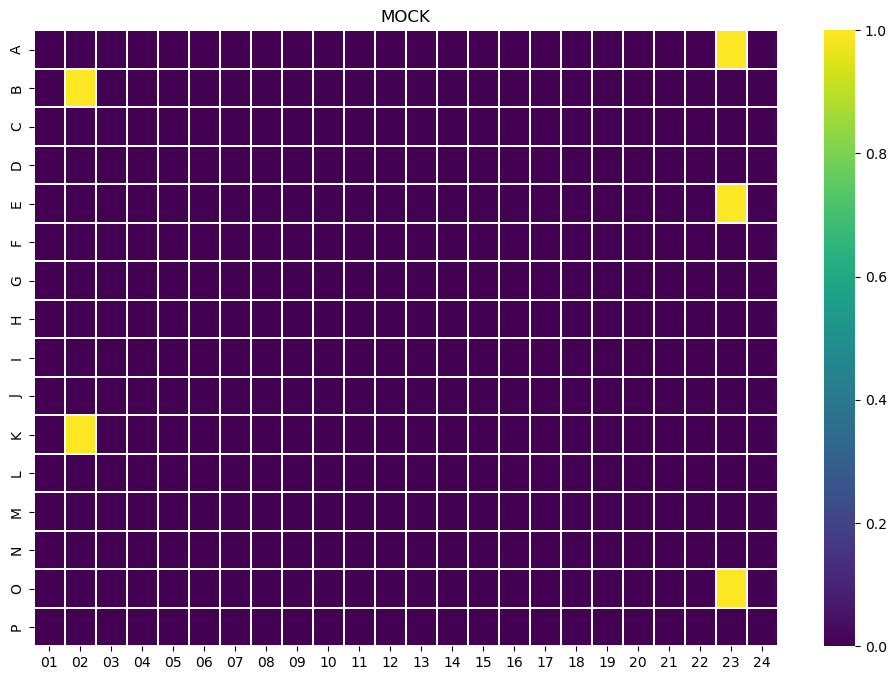

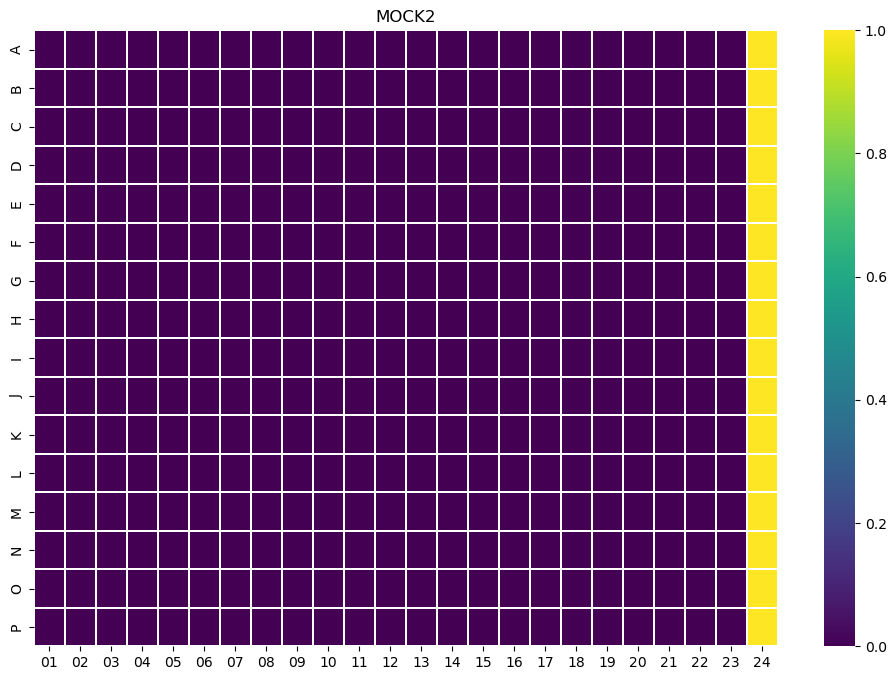

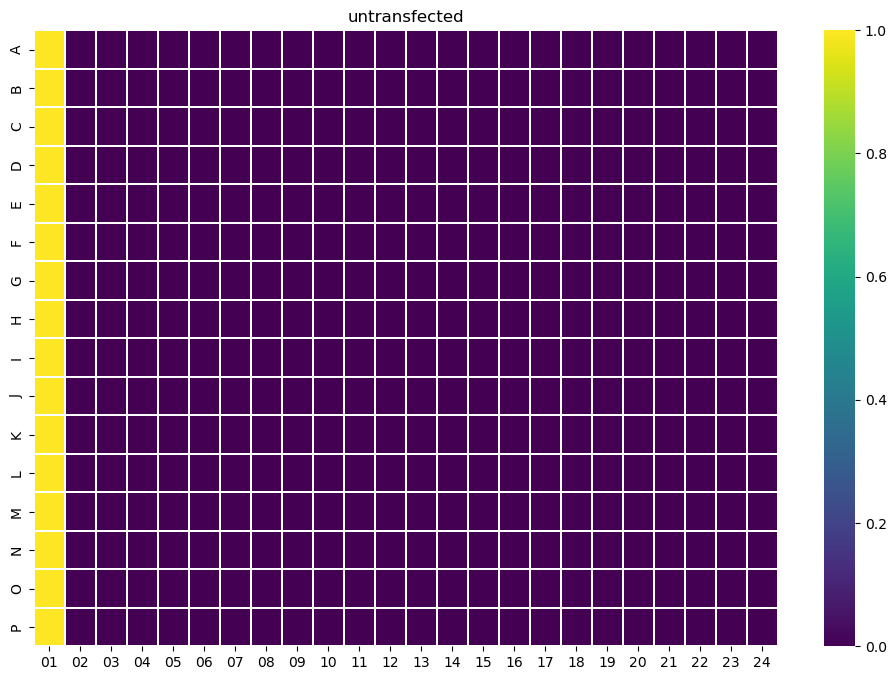

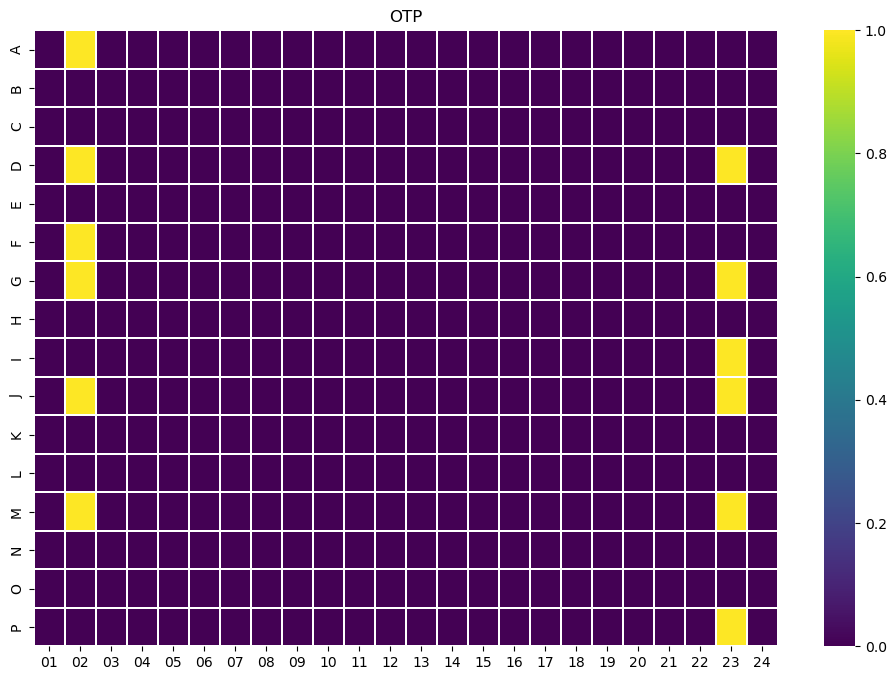

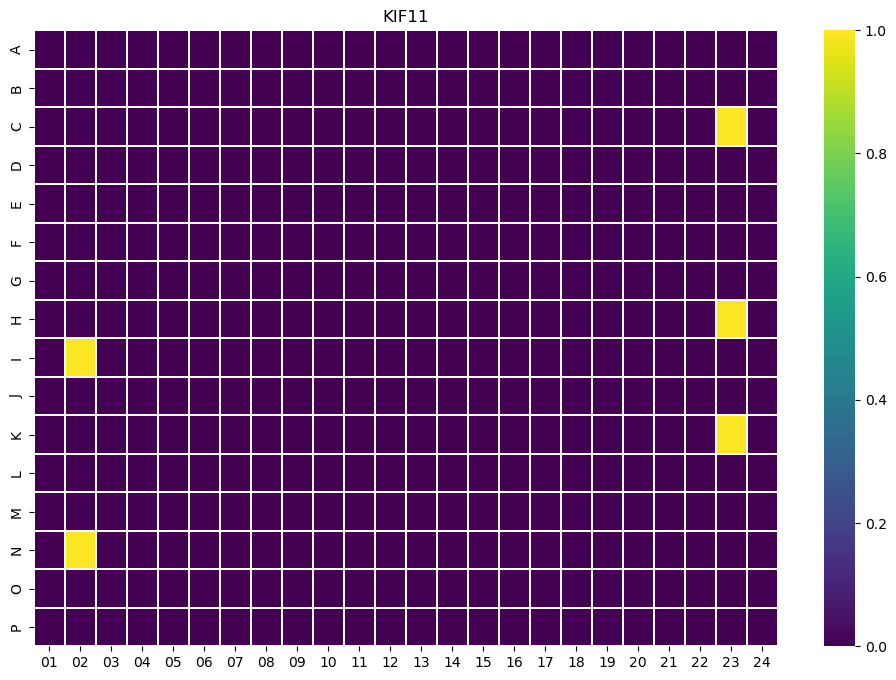

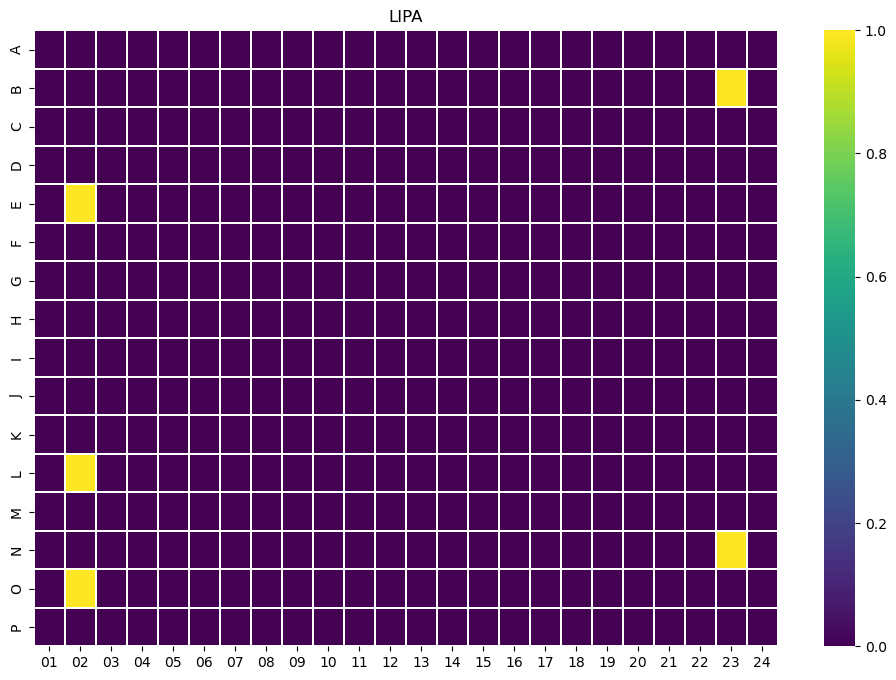

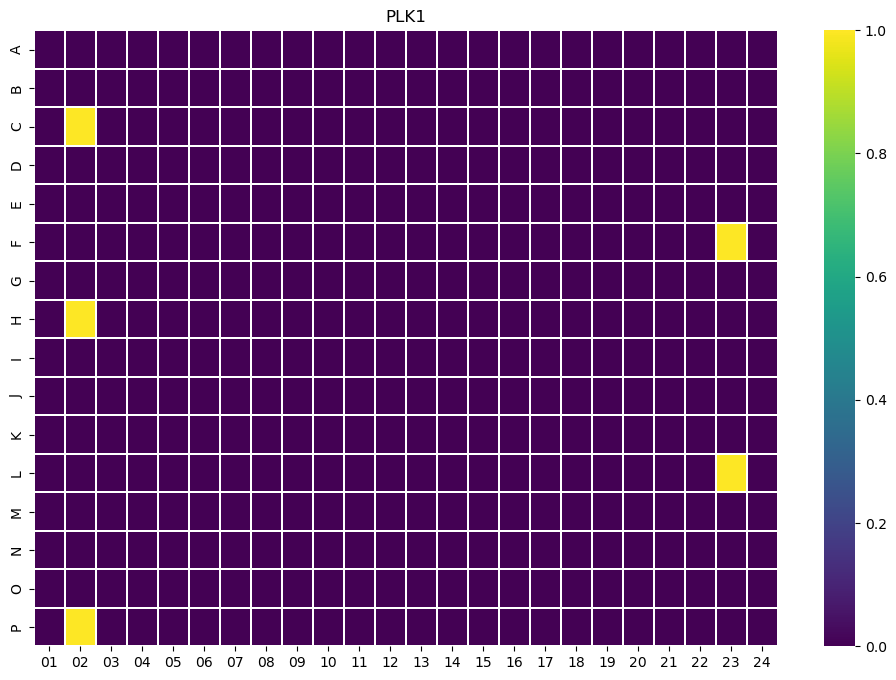

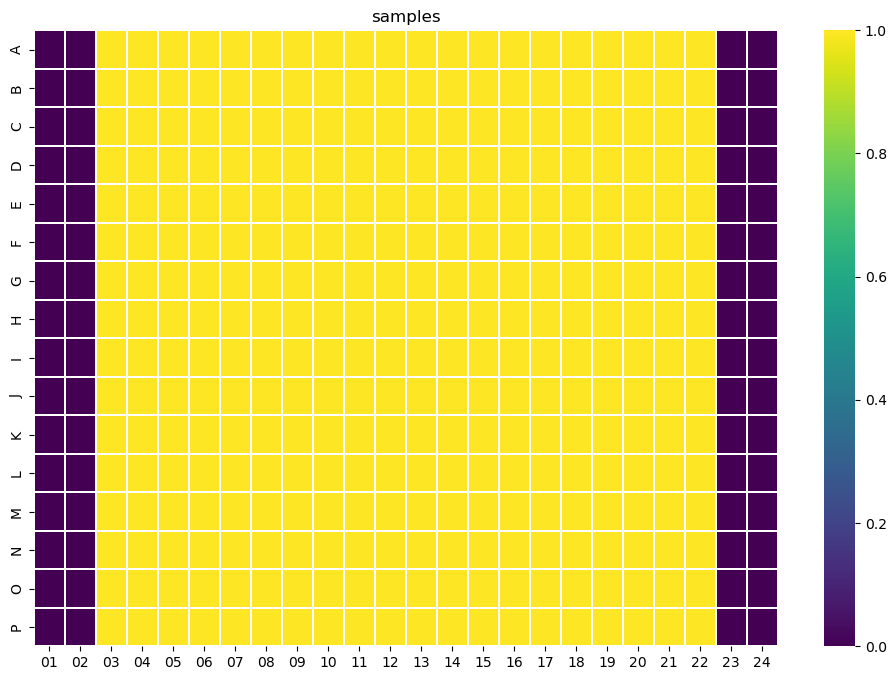

In [35]:
## This cell is important for defining control and sample columns
##necessary for plots

import numpy as np
import pandas as pd
row_number = ['A','B','C','D','E','F','G','H','I','J','K','L','M','N','O','P']
column_number = ['01','02','03','04','05','06','07','08','09','10','11','12','13','14','15','16','17','18','19','20','21','22','23','24']



### Mock ##########################################
zero_data = np.zeros(shape=(16,24))
mock = pd.DataFrame(zero_data,columns=column_number,index=row_number,dtype=int)
#mock_list_r = !cat control.txt | grep mock | cut -f 1 | cut -b 1
mock_list_r = []
mock_list_c = []

with open("control.txt", "r") as file:
    for line in file:
        if "mock" in line:
            first_field = line.strip().split('\t')[0]
            if first_field:
                mock_list_r.append(first_field[1:4])
                mock_list_c.append(first_field[0])

for c,r in zip(mock_list_c,mock_list_r):
    mock.loc[c, r] = 1

plt.figure(figsize=(12,8))
sns.heatmap(np.array(mock),cmap='viridis',linewidths=0.2,xticklabels=column_number,yticklabels=row_number)
plt.title('MOCK')



### Mock 2 ###################################
zero_data = np.zeros(shape=(16,24))
mock2 = pd.DataFrame(zero_data,columns=column_number,index=row_number,dtype=int)

mock2_list_r = []
mock2_list_c = []

with open("control.txt", "r") as file:
    for line in file:
        if "Mock2" in line:
            first_field = line.strip().split('\t')[0]
            if first_field:
                mock2_list_r.append(first_field[1:4])
                mock2_list_c.append(first_field[0])


for c,r in zip(mock2_list_c,mock2_list_r):
    mock2.loc[c,r] = 1
plt.figure(figsize=(12,8))
sns.heatmap(np.array(mock2),cmap='viridis',linewidths=0.2,xticklabels=column_number,yticklabels=row_number)
plt.title('MOCK2')
##################################################

#### unstransfected wells ########################
untr_list_r = []
untr_list_c = []
zero_data = np.zeros(shape=(16,24))
untr = pd.DataFrame(zero_data,columns=column_number,index=row_number,dtype=int)
with open ("control.txt","r") as file:
    for line in file:
        if 'untransfected' in line:
            first_field = line.strip().split('\t')[0]
            if first_field:
                untr_list_c.append(first_field[0])
                untr_list_r.append(first_field[1:4])

for c,r in zip(untr_list_c,untr_list_r):
    untr.loc[c,r] = 1
plt.figure(figsize=(12,8))
sns.heatmap(np.array(untr),cmap='viridis',linewidths=0.2,xticklabels=column_number,yticklabels=row_number)
plt.title('untransfected')

###################################################
###############OTP ###############################

zero_data = np.zeros(shape=(16,24))
OTP = pd.DataFrame(zero_data,columns=column_number,index=row_number)
OTP_list_r = []
OTP_list_c = []

with open ("control.txt","r") as file:
    for line in file:
        if 'OTP' in line:
            first_field = line.strip().split('\t')[0]
            if first_field:
                OTP_list_c.append(first_field[0])
                OTP_list_r.append(first_field[1:4])


for c,r in zip(OTP_list_c,OTP_list_r):
    OTP.loc[c,r] = 1
plt.figure(figsize=(12,8))
sns.heatmap(np.array(OTP),cmap='viridis',linewidths=0.2,xticklabels=column_number,yticklabels=row_number)
plt.title('OTP')



#################### KIF11 ######################
KIF11_list_c = []
KIF11_list_r = []

zero_data = np.zeros(shape=(16,24))
KIF11 = pd.DataFrame(zero_data,columns=column_number,index=row_number)
with open ("control.txt","r") as file:
    for line in file:
        if 'KIF11' in line:
            first_field = line.strip().split('\t')[0]
            if first_field:
                KIF11_list_c.append(first_field[0])
                KIF11_list_r.append(first_field[1:4])



for c,r in zip(KIF11_list_c,KIF11_list_r):
    KIF11.loc[c,r] = 1
plt.figure(figsize=(12,8))
sns.heatmap(np.array(KIF11),cmap='viridis',linewidths=0.2,xticklabels=column_number,yticklabels=row_number)
plt.title('KIF11')
  
###############################################
# #######################LIPA #################  
LIPA_list_r = []
LIPA_list_c = []
zero_data = np.zeros(shape=(16,24))
LIPA=pd.DataFrame(zero_data,columns=column_number,index=row_number)
with open ("control.txt","r") as file:
    for line in file:
        if 'LIPA' in line:
            first_field = line.strip().split('\t')[0]
            if first_field:
                LIPA_list_c.append(first_field[0])
                LIPA_list_r.append(first_field[1:4])   

for c,r in zip(LIPA_list_c,LIPA_list_r):
    LIPA.loc[c,r] = 1
plt.figure(figsize=(12,8))
sns.heatmap(np.array(LIPA),cmap='viridis',linewidths=0.2,xticklabels=column_number,yticklabels=row_number)
plt.title('LIPA')
###############################################
####################### PLK1 ##################
PLK1_list_c=[]
PLK1_list_r=[]
zero_data = np.zeros(shape=(16,24))
PLK1=pd.DataFrame(zero_data,columns=column_number,index=row_number)
with open ("control.txt","r") as file:
    for line in file:
        if 'PLK1' in line:
            first_field = line.strip().split('\t')[0]
            if first_field:
                PLK1_list_c.append(first_field[0])
                PLK1_list_r.append(first_field[1:4])
for c,r in zip(PLK1_list_c,PLK1_list_r):
    PLK1.loc[c,r] = 1
plt.figure(figsize=(12,8))
sns.heatmap(np.array(PLK1),cmap='viridis',linewidths=0.2,xticklabels=column_number,yticklabels=row_number)
plt.title('PLK1')

###############################################

zero_data = np.ones(shape=(16,24))
wells=pd.DataFrame(zero_data,columns=column_number,index=row_number)
samples = wells-mock-mock2-LIPA-KIF11-OTP-untr-PLK1

plt.figure(figsize=(12,8))
sns.heatmap(np.array(samples),cmap='viridis',linewidths=0.2,xticklabels=column_number,yticklabels=row_number)
plt.title('samples')




The next cell is important for plate Number
Always run before each plot

### BUG

There was a problem in 20170717-SA-12005-68C MFGTMPcx7_170723090001 J23 well which is an OTP well. The problem was the blurriness of images in that well and the result was very huge objects (model segmented the shadow)
and the area number for this OTP was so large. I have to fix it by removing J23 well from .csv results and other results. I just made the value of J23=0 for count and area

['J23\\MFGTMPcx7_170723090001_J23f00d0.png', 'J23\\MFGTMPcx7_170723090001_J23f01d0.png', 'J23\\MFGTMPcx7_170723090001_J23f02d0.png', 'J23\\MFGTMPcx7_170723090001_J23f03d0.png', 'J23\\MFGTMPcx7_170723090001_J23f04d0.png', 'J23\\MFGTMPcx7_170723090001_J23f05d0.png', 'J23\\MFGTMPcx7_170723090001_J23f06d0.png', 'J23\\MFGTMPcx7_170723090001_J23f07d0.png', 'J23\\MFGTMPcx7_170723090001_J23f08d0.png', 'J23\\MFGTMPcx7_170723090001_J23f09d0.png', 'J23\\MFGTMPcx7_170723090001_J23f10d0.png', 'J23\\MFGTMPcx7_170723090001_J23f11d0.png', 'J23\\MFGTMPcx7_170723090001_J23f12d0.png', 'J23\\MFGTMPcx7_170723090001_J23f13d0.png', 'J23\\MFGTMPcx7_170723090001_J23f14d0.png', 'J23\\MFGTMPcx7_170723090001_J23f15d0.png']


<Figure size 640x480 with 0 Axes>

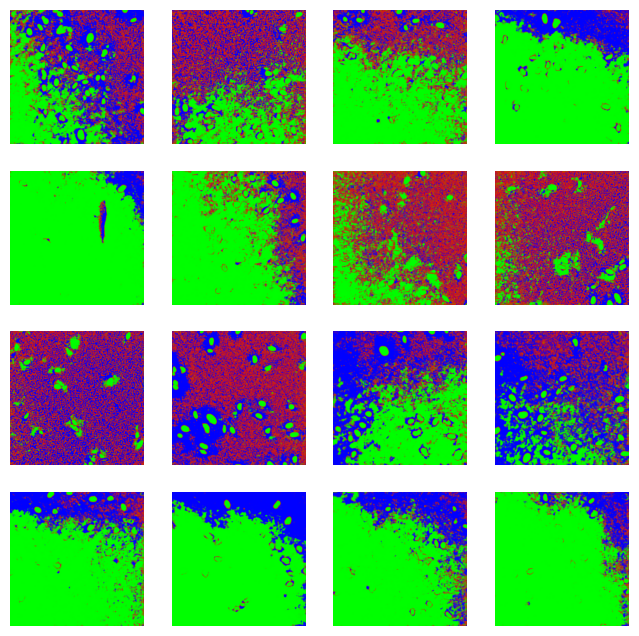

In [ ]:
import glob
import matplotlib.pyplot as plt
import cv2

%matplotlib inline
images = glob.glob('J23/*.png')
print(images)
plt.figure()

fig, axes = plt.subplots(4, 4, figsize=(8, 8))


for i, ax in zip(images,axes.flat):
    x = cv2.imread(i)
    ax.imshow(x)
    
    ax.axis('off')
    

### Don't run the next cell
It is for creating count or area matrix
run only if you do not have .json files and want to create from .csv file

Other wise DO NOT run

In [ ]:
plateNr = !ls csv_files/C/*_count.json | cut -d '_' -f 3 | sed s/'.csv'/''/g
plateNr

In [7]:
# this is for number of cells
row_number = ['A','B','C','D','E','F','G','H','I','J','K','L','M','N','O','P']
column_number = ['01','02','03','04','05','06','07','08','09','10','11','12','13','14','15','16','17','18','19','20','21','22','23','24']

#Create empty list
my_dict_cellNr = {}

# Access the value using the key
#my_dict_cellNr["170524210001"] 
for p in plateNr:
    temp_df = pd.read_csv('csv_files/C/MFGTMPcx7_'+p+'.csv')
    new_df_cell_number = pd.DataFrame(columns=column_number,index=row_number)
    for r in row_number:
        for c in column_number:
            well = r+c
            new_df_cell_number.loc[r][c] = len(temp_df[temp_df['Image_name'].str.contains(p+'_'+well)]['Area']) #len function counts cells
    my_dict_cellNr[p]=new_df_cell_number


### Don't run the next cell
It is for saving .json files of _count or _area
run only if you do not have .json files and want to create from .csv file run it after previous cell

In [8]:
# Saves dictionaries in json files, remove names of plates you already have jsons for in cell above before running
import json
for k in my_dict_cellNr.keys():
    json.dump(my_dict_cellNr[k].to_json(orient='split'), open('csv_files/C/'+k+'_count.json', 'w'))
    

### Run the following cell if you are going to plot _count plots (raw and normalized)

In [127]:
Barcode_C   = [ba for ba in barcode_plate['Barcode'] if ba.endswith('C')]
print(len(Barcode_C))
Barcode_C  


58


['20170516-SA-12022-01C',
 '20170516-SA-12023-02C',
 '20170516-SA-12024-03C',
 '20170516-SA-12025-04C',
 '20170522-SA-12026-05C',
 '20170522-SA-12027-06C',
 '20170522-SA-12028-07C',
 '20170522-SA-12029-08C',
 '20170523-SA-12030-09C',
 '20170523-SA-12031-10C',
 '20170523-SA-12032-11C',
 '20170529-SA-12034-13C',
 '20170529-SA-12035-14C',
 '20170529-SA-12036-15C',
 '20170530-SA-12038-17C',
 '20170530-SA-12039-18C',
 '20170530-SA-12040-19C',
 '20170613-SA-12050-29C',
 '20170613-SA-12051-30C',
 '20170613-SA-12052-31C',
 '20170614-SA-12054-33C',
 '20170614-SA-12055-34C',
 '20170614-SA-12056-35C',
 '20170614-SA-12057-36C',
 '20170619-SA-12058-37C',
 '20170619-SA-12001-38C',
 '20170619-SA-12002-39C',
 '20170626-SA-12008-45C',
 '20170626-SA-12009-46C',
 '20170626-SA-12010-47C',
 '20170626-SA-12011-48C',
 '20170627-SA-12012-49C',
 '20170703-SA-12016-53C',
 '20170703-SA-12017-54C',
 '20170703-SA-12018-55C',
 '20170704-SA-12020-57C',
 '20170704-SA-12021-58C',
 '20170704-SA-12042-59C',
 '20170704-S

In [116]:
Barcode_C   = glob.glob('csv_files/C/*.csv')
Barcode_C  
print(len(Barcode_C))

57


C:\Users\salma\AppData\Local\Temp\ipykernel_28316\2804002750.py:59: RuntimeWarning: Mean of empty slice.
  otp_avg =  OTP_per_plate[np.nonzero(OTP_per_plate)].mean()


58


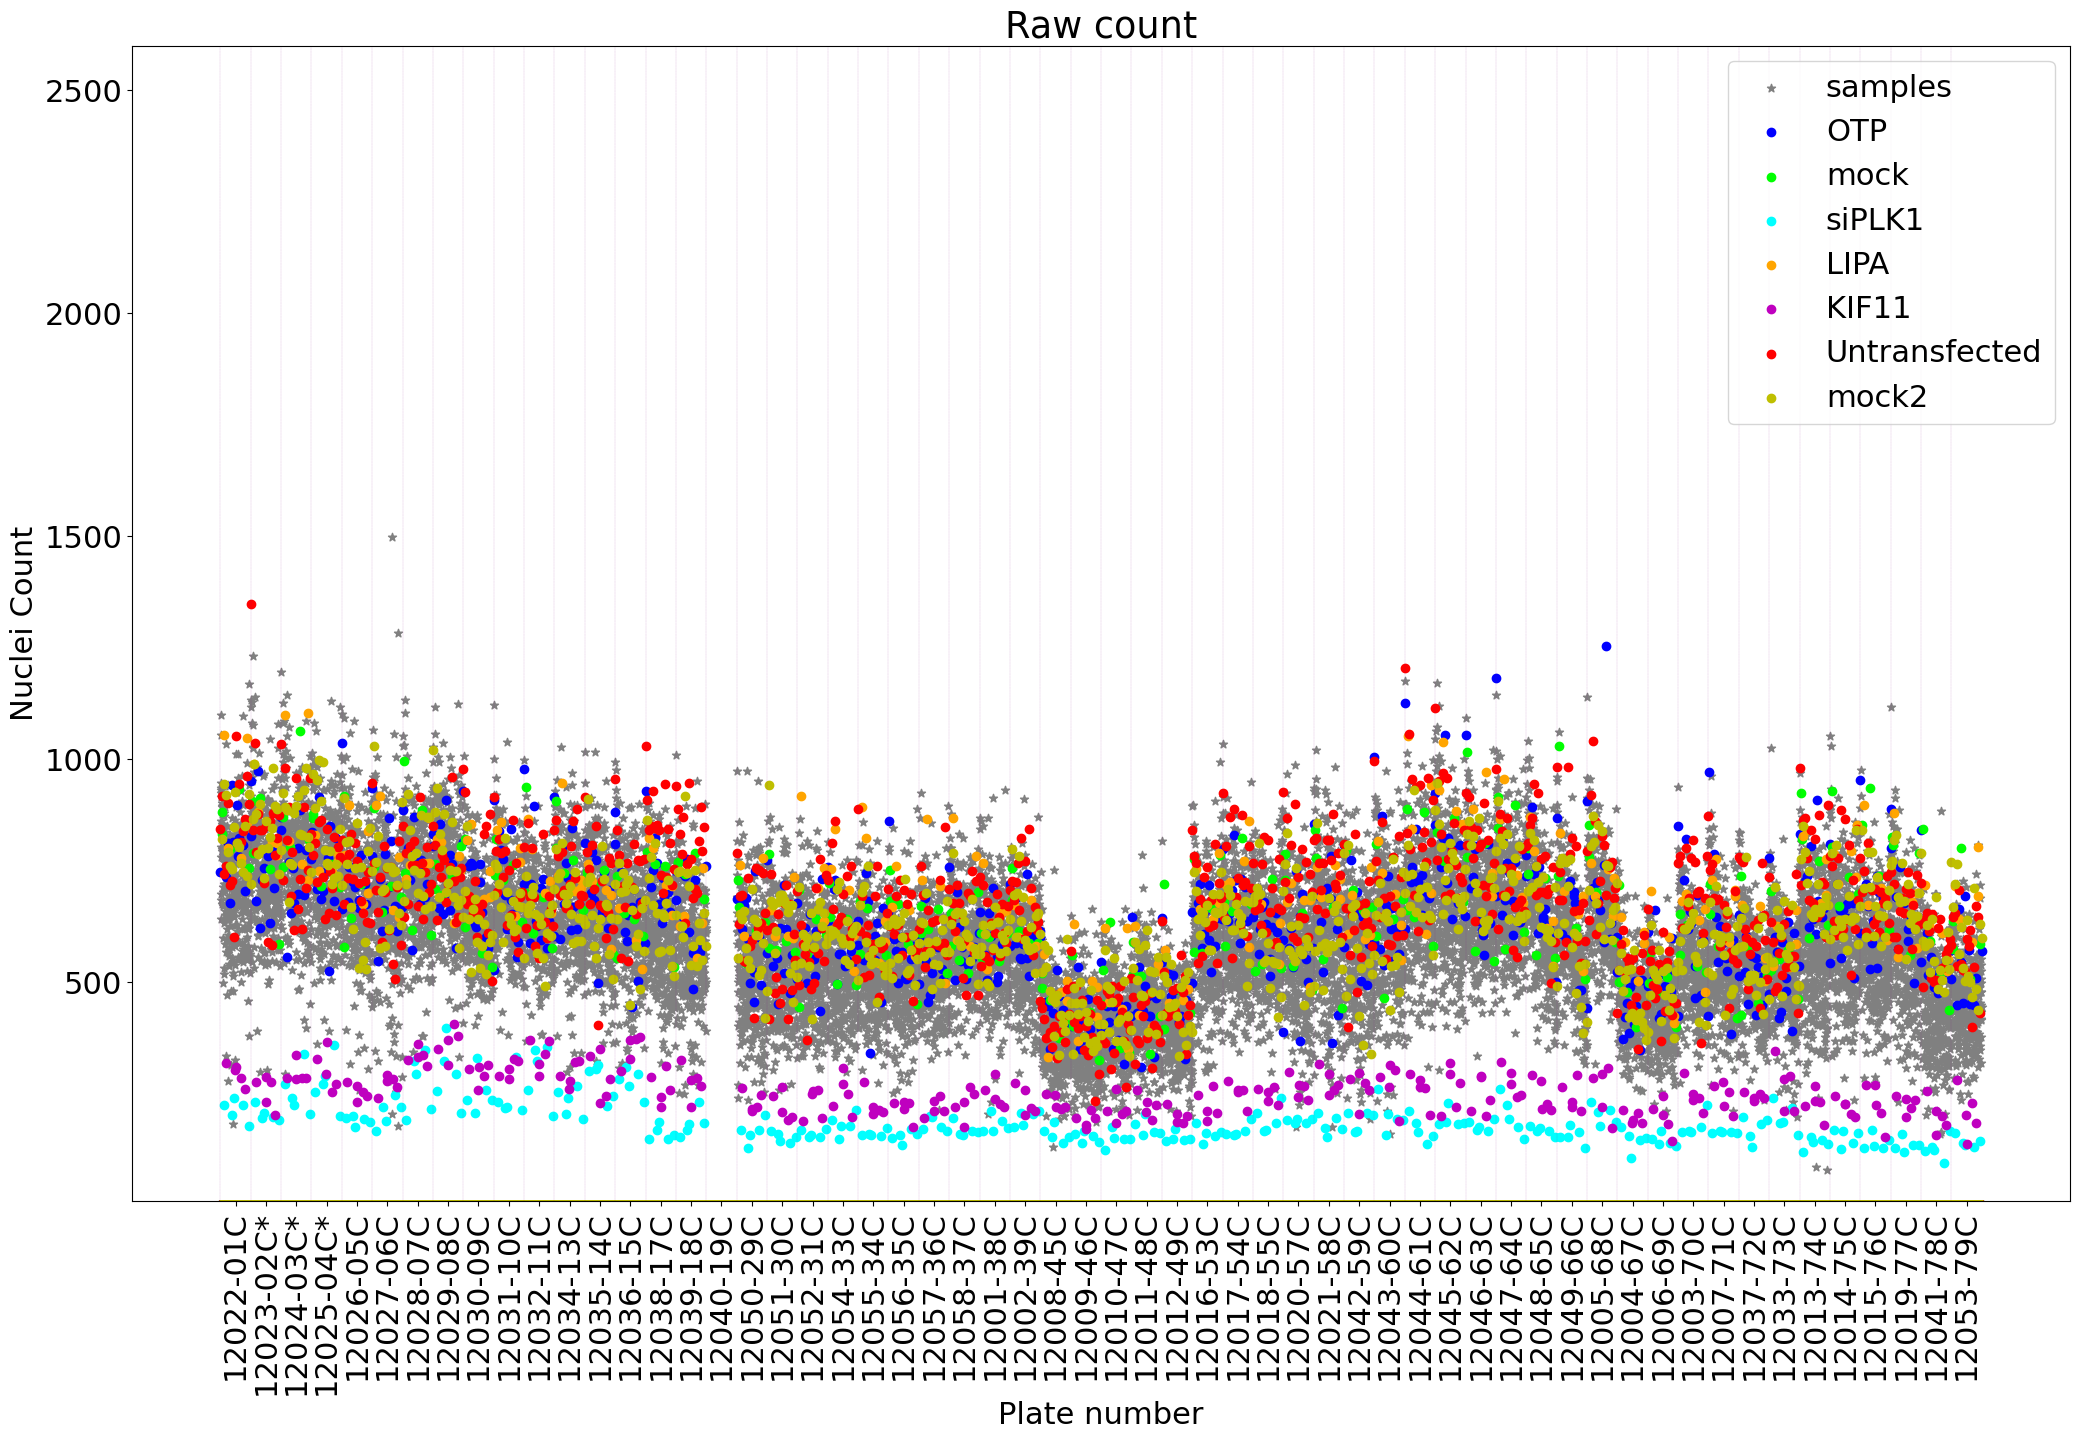

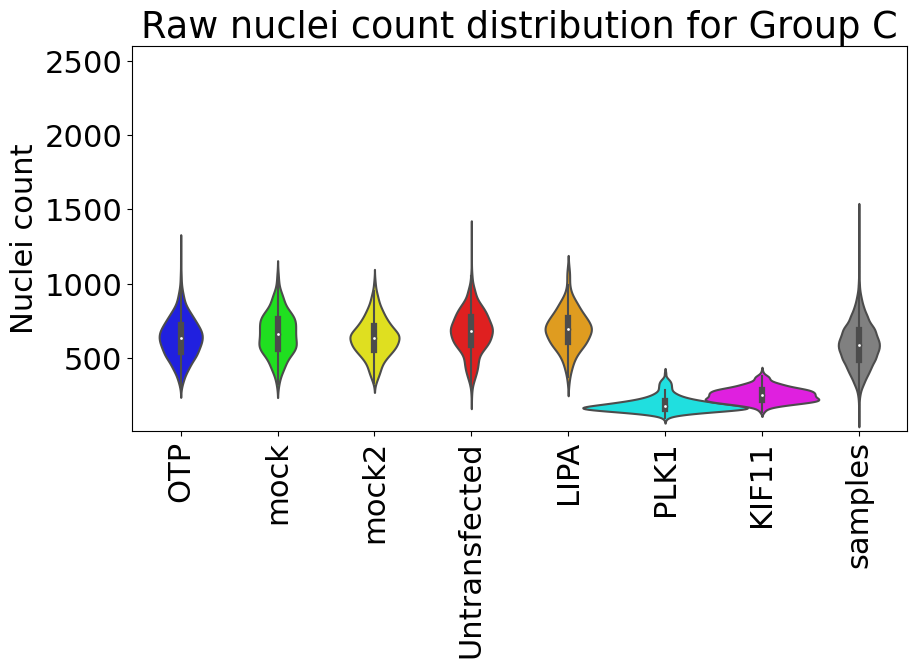

In [11]:
#COPY
# Reads saved json files

#import json so you dont have to run above cell if no new files needs saving
import json
import numpy as np
import os

#make all jsonfiles into keys


#create empty list
l = []
mock_well = []
OTP_well  = []
KIF11_well =[]
LIPA_well = []
PLK1_well = []
mock2_well= []
untr_well = []
label_X = []
all_plate_well = []

#loop through all keys (jsonfiles), load, add key to the empty list l
for k in Barcode_C:
    f4 = barcode_plate.loc[barcode_plate['Barcode']==k,'4fields'].values[0]
    
    lb = k.split('-SA-')[1]+str((bool(f4))).replace('True','*').replace('False','')
    label_X.append(lb)
    plate_data = np.zeros([16,24])
    pl   = barcode_plate.loc[barcode_plate['Barcode']==k, 'Plate'].values[0]

    if len(pl) != 0:
        with open('csv_files/C/'+pl.replace('MFGTMPcx7_','')+'_count.json','r') as f:
        
        ###Normalizing to avg of OTP wells
            json_str   = json.load(f)
            json_dict  = json.loads(json_str)
            plate_data = np.array(json_dict['data'])
             ##OTP


            ## This whole part is for adding 4 more field##
            P_ID  = pl
            
            ff =barcode_plate.loc[barcode_plate['Plate']==P_ID, '4fields'].values[0]
            fourfields = 'csv_files/C/4field/'+ff.replace('MFGTMPcx7_','')+'_count.json'
            if os.path.exists(fourfields):
                with open(fourfields,'r') as f:
                    second_json_4fields = json.load(f)
                    second_json_dict_4fields = json.loads(second_json_4fields)


                    second_plate_data = np.array(second_json_dict_4fields['data'])
                    plate_data = (plate_data+second_plate_data)*0.8


    OTP_per_plate =plate_data *np.array(OTP)
    otp_avg =  OTP_per_plate[np.nonzero(OTP_per_plate)].mean()
    plate_data = plate_data


    ##samples
    l.append(plate_data*np.array(samples))

    ##controls
    mock_well.append(plate_data*np.array(mock))
    OTP_well.append(plate_data*np.array(OTP))
    KIF11_well.append(plate_data*np.array(KIF11))
    LIPA_well.append(plate_data*np.array(LIPA))
    PLK1_well.append(plate_data*np.array(PLK1))
    mock2_well.append(plate_data*np.array(mock2))
    untr_well.append(plate_data*np.array(untr))

    all_plate_well.append(plate_data)
      
            

          
    

#label_X= plateNr
print(len(label_X))
       
#make list into array
array_all_plates = np.array(l)
mock_plates = np.array(mock_well)
OTP_plates = np.array(OTP_well)
KIF11_plates = np.array(KIF11_well)
LIPA_plates = np.array(LIPA_well)
PLK1_plates = np.array(PLK1_well)
untr_plates = np.array(untr_well)
mock2_plates = np.array(mock2_well)


all_plates = np.array(all_plate_well)


num_of_plates = len(Barcode_C)


all_for_plot = np.zeros([1,num_of_plates*384])
mock_for_plot = np.zeros([1,num_of_plates*384])
OTP_for_plot = np.zeros([1,num_of_plates*384])
KIF11_for_plot = np.zeros([1,num_of_plates*384])
LIPA_for_plot = np.zeros([1,num_of_plates*384])
PLK1_for_plot = np.zeros([1,num_of_plates*384])
untr_for_plot = np.zeros([1,num_of_plates*384])
mock2_for_plot = np.zeros([1,num_of_plates*384])

all_plate_for_plot = np.zeros([1,num_of_plates*384])

for plate_n in range(num_of_plates):
    wells = np.reshape(array_all_plates[plate_n,:,:],(1,384))
    all_for_plot[0,plate_n*384:(plate_n+1)*(384)]= wells

    mock_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(mock_plates[plate_n,:,:],(1,384))
    OTP_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(OTP_plates[plate_n,:,:],(1,384))
    KIF11_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(KIF11_plates[plate_n,:,:],(1,384))
    LIPA_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(LIPA_plates[plate_n,:,:],(1,384))
    PLK1_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(PLK1_plates[plate_n,:,:],(1,384))
    untr_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(untr_plates[plate_n,:,:],(1,384))
    mock2_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(mock2_plates[plate_n,:,:],(1,384))
    
    all_plate_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(all_plates[plate_n,:,:],(1,384)) 
    

#fig = plt.figure(figsize=(15,20))
#ax1 = fig.add_axes([0.1, 0.1, 0.8, 0.8]) # main axes

fig, ax1 = plt.subplots(1,1,figsize=(25,15))



plt.scatter(np.arange(all_for_plot.shape[1]),all_for_plot[0],color='gray',marker='*')

plt.scatter(np.arange((OTP_for_plot.shape[1])),OTP_for_plot,color='blue')
plt.scatter(np.arange((mock_for_plot.shape[1])),mock_for_plot,color='lime')

plt.scatter(np.arange((PLK1_for_plot.shape[1])),PLK1_for_plot,color ='cyan')

plt.scatter(np.arange((LIPA_for_plot.shape[1])),LIPA_for_plot,color='orange')
plt.scatter(np.arange((KIF11_for_plot.shape[1])),KIF11_for_plot,color='m')

plt.scatter(np.arange((untr_for_plot.shape[1])),untr_for_plot,color='r')

plt.scatter(np.arange((mock2_for_plot.shape[1])),mock2_for_plot,color='y')


X      = np.arange(num_of_plates)*384

plt.vlines(x=X,ymin=0,ymax=40000,colors='purple', ls='--', lw=0.1)


ax1.set_xticks(X+192)

ax1.set_xticklabels(label_X, rotation=90)
plt.xlabel('Plate number')
plt.ylabel('Nuclei Count')
plt.rcParams.update({'font.size': 22})
plt.ylim([10,2600])
plt.legend(['samples','OTP','mock','siPLK1','LIPA','KIF11','Untransfected','mock2'])
plt.title('Raw count')


fig, ax2 = plt.subplots(1,1,figsize=(10,5))

sns.violinplot([OTP_for_plot[OTP_for_plot>0],mock_for_plot[mock_for_plot>0],
                mock2_for_plot[mock2_for_plot>0],untr_for_plot[untr_for_plot>0],LIPA_for_plot[LIPA_for_plot>0],
                PLK1_for_plot[PLK1_for_plot>0],
                KIF11_for_plot[KIF11_for_plot>0],all_for_plot[all_for_plot>0]],
                palette=['blue','lime','yellow','red','orange','cyan','magenta','gray'],width=1.7)
label_X = ['OTP','mock','mock2','Untransfected','LIPA','PLK1','KIF11','samples']
ax2.set_xticklabels(label_X, rotation=90)
plt.ylabel('Nuclei count')
plt.title('Raw nuclei count distribution for Group C')
plt.ylim([10,2600])


np.save('C_count.npy',all_plate_for_plot,allow_pickle=True)

In [128]:
barcode_plate[:][0:12]

,Barcode,Plate,4fields,4fields_extra
0,20170516-SA-12022-01A,MFGTMPcx7_170525010001,,
1,20170516-SA-12022-01B,MFGTMPcx7_170524170002,,
2,20170516-SA-12022-01C,MFGTMPcx7_170525050001,,
3,20170516-SA-12022-01D,MFGTMPcx7_170524210001,,
4,20170516-SA-12023-02A,MFGTMPcx7_170525090001,MFGTMPcx7_170521130001,
5,20170516-SA-12023-02B,MFGTMPcx7_170719230001,MFGTMPcx7_170521170001,
6,20170516-SA-12023-02C,MFGTMPcx7_170521220001,MFGTMPcx7_170720000001,
7,20170516-SA-12023-02D,MFGTMPcx7_170720020001,MFGTMPcx7_170522030001,
8,20170516-SA-12024-03A,MFGTMPcx7_170720030001,MFGTMPcx7_170522080001,
9,20170516-SA-12024-03B,MFGTMPcx7_170720050001,MFGTMPcx7_170522120001,


C:\Users\salma\AppData\Local\Temp\ipykernel_11052\2804002750.py:59: RuntimeWarning: Mean of empty slice.
  otp_avg =  OTP_per_plate[np.nonzero(OTP_per_plate)].mean()
c:\Users\salma\.conda\envs\SalmaEnv\envs\coderefinery\Lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide


58


C:\Users\salma\AppData\Local\Temp\ipykernel_11052\2804002750.py:174: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(label_X, rotation=90)


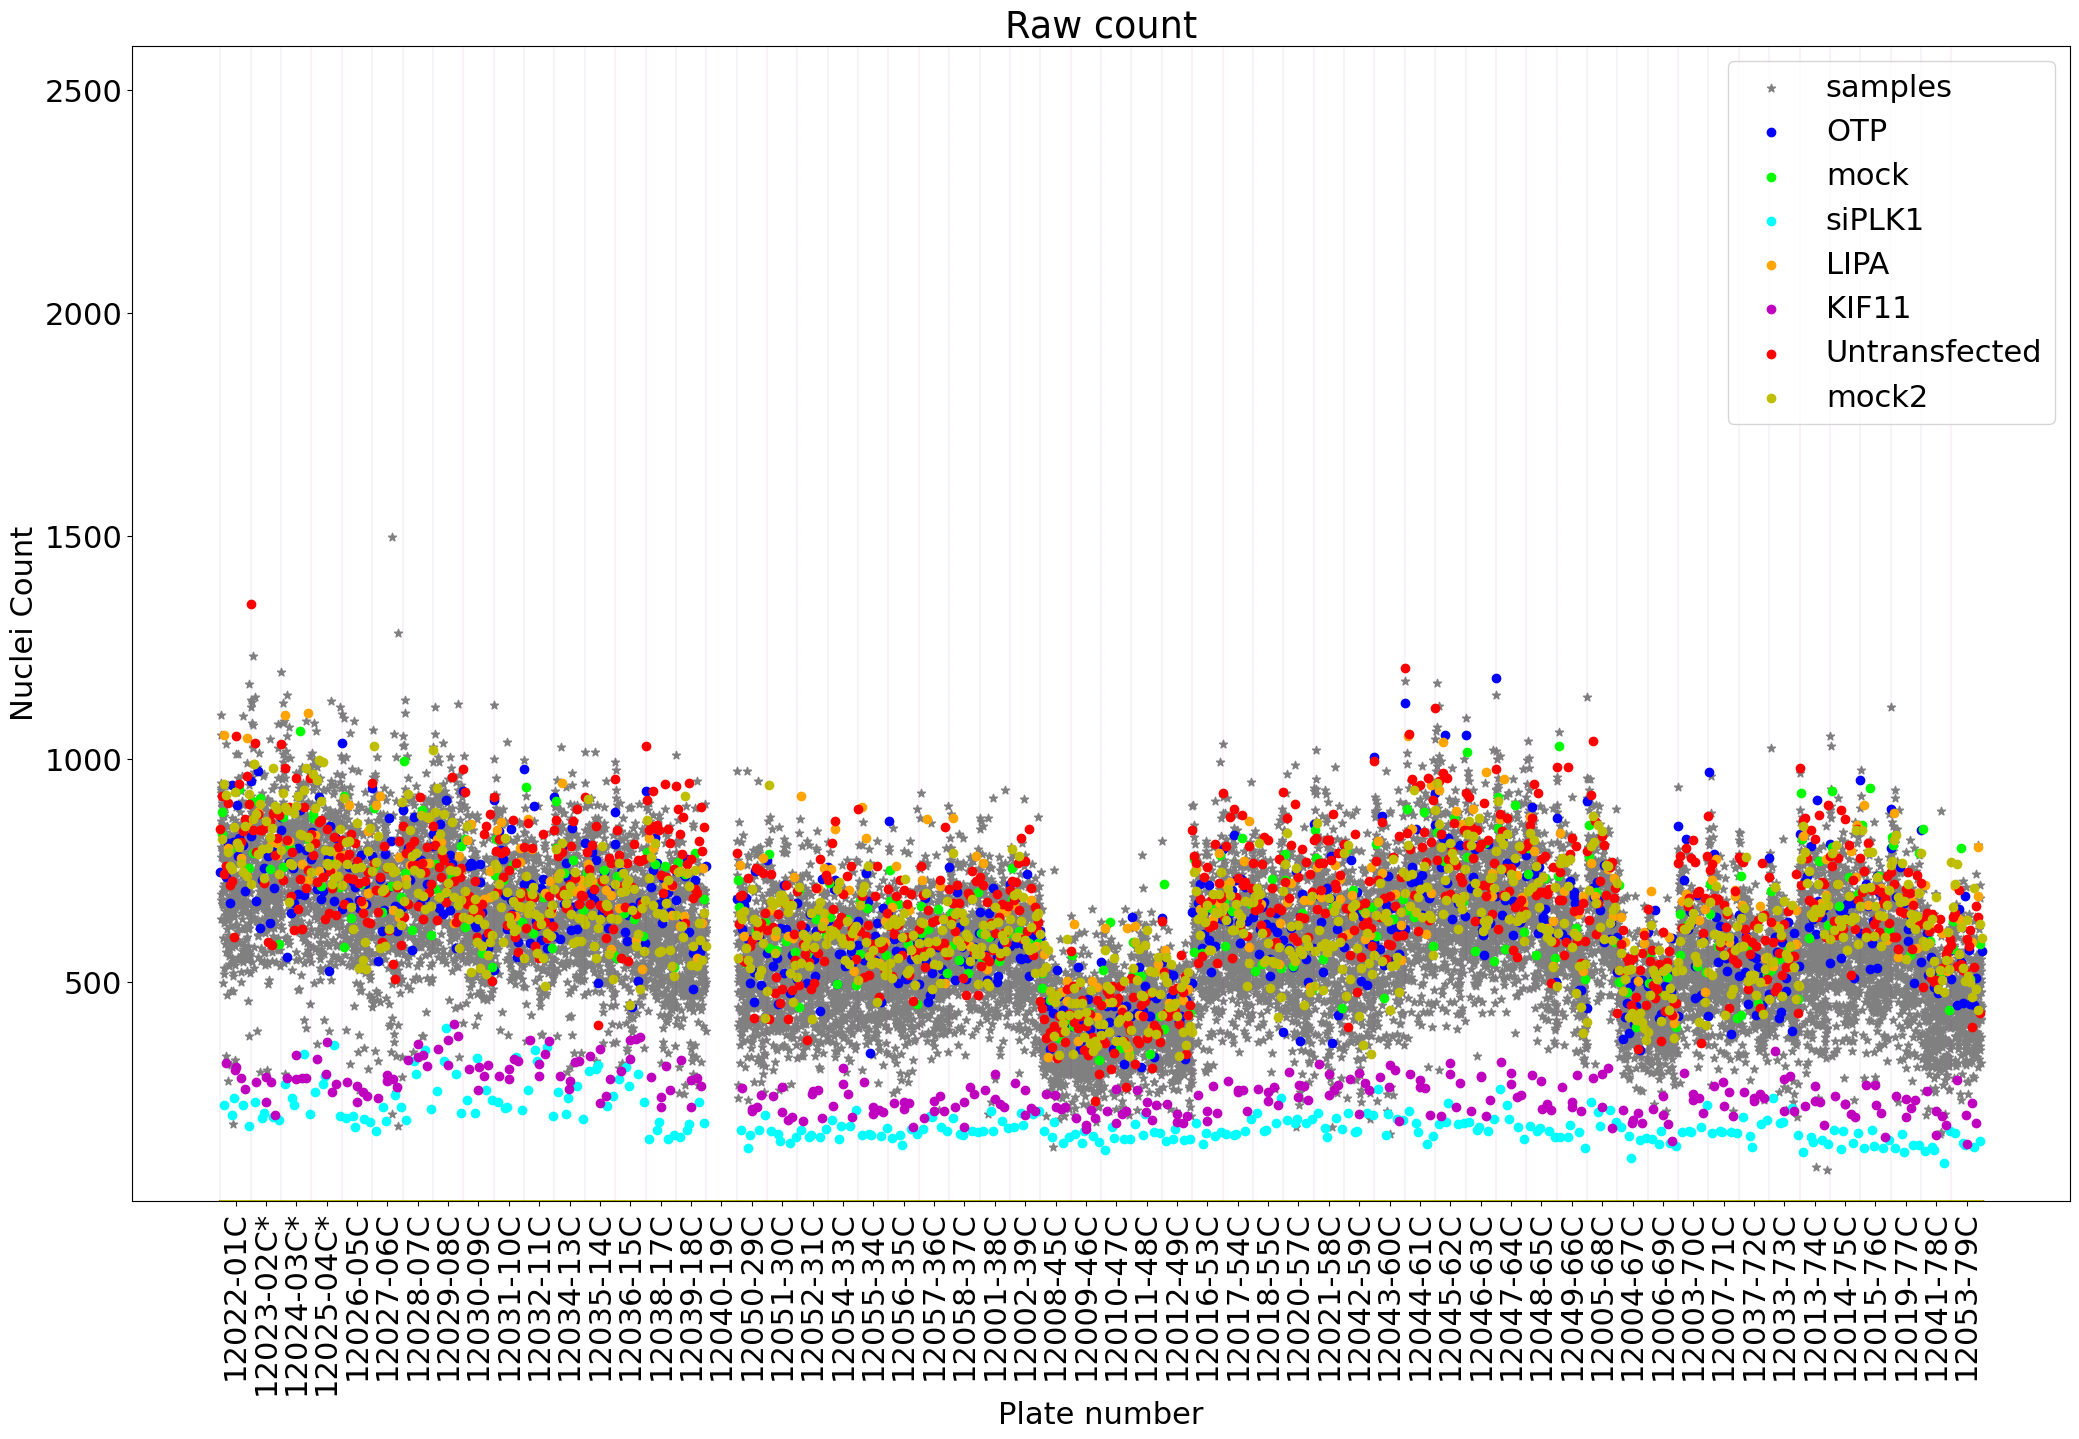

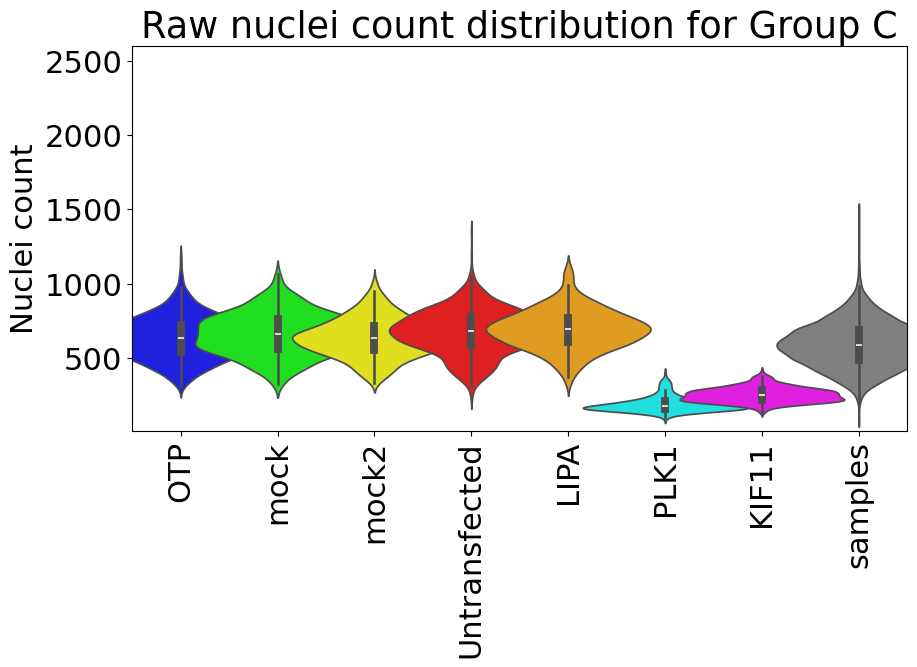

In [130]:
#COPY
# Reads saved json files

#import json so you dont have to run above cell if no new files needs saving
import json
import numpy as np
import os

#make all jsonfiles into keys


#create empty list
l = []
mock_well = []
OTP_well  = []
KIF11_well =[]
LIPA_well = []
PLK1_well = []
mock2_well= []
untr_well = []
label_X = []
all_plate_well = []

#loop through all keys (jsonfiles), load, add key to the empty list l
for k in Barcode_C:
    f4 = barcode_plate.loc[barcode_plate['Barcode']==k,'4fields'].values[0]
    
    lb = k.split('-SA-')[1]+str((bool(f4))).replace('True','*').replace('False','')
    label_X.append(lb)
    plate_data = np.zeros([16,24])
    pl   = barcode_plate.loc[barcode_plate['Barcode']==k, 'Plate'].values[0]

    if len(pl) != 0:
        with open('csv_files/C/'+pl.replace('MFGTMPcx7_','')+'_count.json','r') as f:
        
        ###Normalizing to avg of OTP wells
            json_str   = json.load(f)
            json_dict  = json.loads(json_str)
            plate_data = np.array(json_dict['data'])
             ##OTP


            ## This whole part is for adding 4 more field##
            P_ID  = pl
            
            ff =barcode_plate.loc[barcode_plate['Plate']==P_ID, '4fields'].values[0]
            fourfields = 'csv_files/C/4field/'+ff.replace('MFGTMPcx7_','')+'_count.json'
            if os.path.exists(fourfields):
                with open(fourfields,'r') as f:
                    second_json_4fields = json.load(f)
                    second_json_dict_4fields = json.loads(second_json_4fields)


                    second_plate_data = np.array(second_json_dict_4fields['data'])
                    plate_data = (plate_data+second_plate_data)*0.8


    OTP_per_plate =plate_data *np.array(OTP)
    otp_avg =  OTP_per_plate[np.nonzero(OTP_per_plate)].mean()
    plate_data = plate_data


    ##samples
    l.append(plate_data*np.array(samples))

    ##controls
    mock_well.append(plate_data*np.array(mock))
    OTP_well.append(plate_data*np.array(OTP))
    KIF11_well.append(plate_data*np.array(KIF11))
    LIPA_well.append(plate_data*np.array(LIPA))
    PLK1_well.append(plate_data*np.array(PLK1))
    mock2_well.append(plate_data*np.array(mock2))
    untr_well.append(plate_data*np.array(untr))

    all_plate_well.append(plate_data)
      
            

          
    

#label_X= plateNr
print(len(label_X))
       
#make list into array
array_all_plates = np.array(l)
mock_plates = np.array(mock_well)
OTP_plates = np.array(OTP_well)
KIF11_plates = np.array(KIF11_well)
LIPA_plates = np.array(LIPA_well)
PLK1_plates = np.array(PLK1_well)
untr_plates = np.array(untr_well)
mock2_plates = np.array(mock2_well)


all_plates = np.array(all_plate_well)


num_of_plates = len(Barcode_C)


all_for_plot = np.zeros([1,num_of_plates*384])
mock_for_plot = np.zeros([1,num_of_plates*384])
OTP_for_plot = np.zeros([1,num_of_plates*384])
KIF11_for_plot = np.zeros([1,num_of_plates*384])
LIPA_for_plot = np.zeros([1,num_of_plates*384])
PLK1_for_plot = np.zeros([1,num_of_plates*384])
untr_for_plot = np.zeros([1,num_of_plates*384])
mock2_for_plot = np.zeros([1,num_of_plates*384])

all_plate_for_plot = np.zeros([1,num_of_plates*384])

for plate_n in range(num_of_plates):
    wells = np.reshape(array_all_plates[plate_n,:,:],(1,384))
    all_for_plot[0,plate_n*384:(plate_n+1)*(384)]= wells

    mock_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(mock_plates[plate_n,:,:],(1,384))
    OTP_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(OTP_plates[plate_n,:,:],(1,384))
    KIF11_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(KIF11_plates[plate_n,:,:],(1,384))
    LIPA_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(LIPA_plates[plate_n,:,:],(1,384))
    PLK1_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(PLK1_plates[plate_n,:,:],(1,384))
    untr_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(untr_plates[plate_n,:,:],(1,384))
    mock2_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(mock2_plates[plate_n,:,:],(1,384))
    
    all_plate_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(all_plates[plate_n,:,:],(1,384)) 
    

#fig = plt.figure(figsize=(15,20))
#ax1 = fig.add_axes([0.1, 0.1, 0.8, 0.8]) # main axes

fig, ax1 = plt.subplots(1,1,figsize=(25,15))



plt.scatter(np.arange(all_for_plot.shape[1]),all_for_plot[0],color='gray',marker='*')

plt.scatter(np.arange((OTP_for_plot.shape[1])),OTP_for_plot,color='blue')
plt.scatter(np.arange((mock_for_plot.shape[1])),mock_for_plot,color='lime')

plt.scatter(np.arange((PLK1_for_plot.shape[1])),PLK1_for_plot,color ='cyan')

plt.scatter(np.arange((LIPA_for_plot.shape[1])),LIPA_for_plot,color='orange')
plt.scatter(np.arange((KIF11_for_plot.shape[1])),KIF11_for_plot,color='m')

plt.scatter(np.arange((untr_for_plot.shape[1])),untr_for_plot,color='r')

plt.scatter(np.arange((mock2_for_plot.shape[1])),mock2_for_plot,color='y')


X      = np.arange(num_of_plates)*384

plt.vlines(x=X,ymin=0,ymax=40000,colors='purple', ls='--', lw=0.1)


ax1.set_xticks(X+192)

ax1.set_xticklabels(label_X, rotation=90)
plt.xlabel('Plate number')
plt.ylabel('Nuclei Count')
plt.rcParams.update({'font.size': 22})
plt.ylim([10,2600])
plt.legend(['samples','OTP','mock','siPLK1','LIPA','KIF11','Untransfected','mock2'])
plt.title('Raw count')


fig, ax2 = plt.subplots(1,1,figsize=(10,5))

sns.violinplot([OTP_for_plot[OTP_for_plot>0],mock_for_plot[mock_for_plot>0],
                mock2_for_plot[mock2_for_plot>0],untr_for_plot[untr_for_plot>0],LIPA_for_plot[LIPA_for_plot>0],
                PLK1_for_plot[PLK1_for_plot>0],
                KIF11_for_plot[KIF11_for_plot>0],all_for_plot[all_for_plot>0]],
                palette=['blue','lime','yellow','red','orange','cyan','magenta','gray'],width=1.7)
label_X = ['OTP','mock','mock2','Untransfected','LIPA','PLK1','KIF11','samples']
ax2.set_xticklabels(label_X, rotation=90)
plt.ylabel('Nuclei count')
plt.title('Raw nuclei count distribution for Group C')
plt.ylim([10,2600])


np.save('C_count.npy',all_plate_for_plot,allow_pickle=True)

C:\Users\salma\AppData\Local\Temp\ipykernel_28316\1510727801.py:58: RuntimeWarning: Mean of empty slice.
  otp_avg =  OTP_per_plate[np.nonzero(OTP_per_plate)].mean()


58


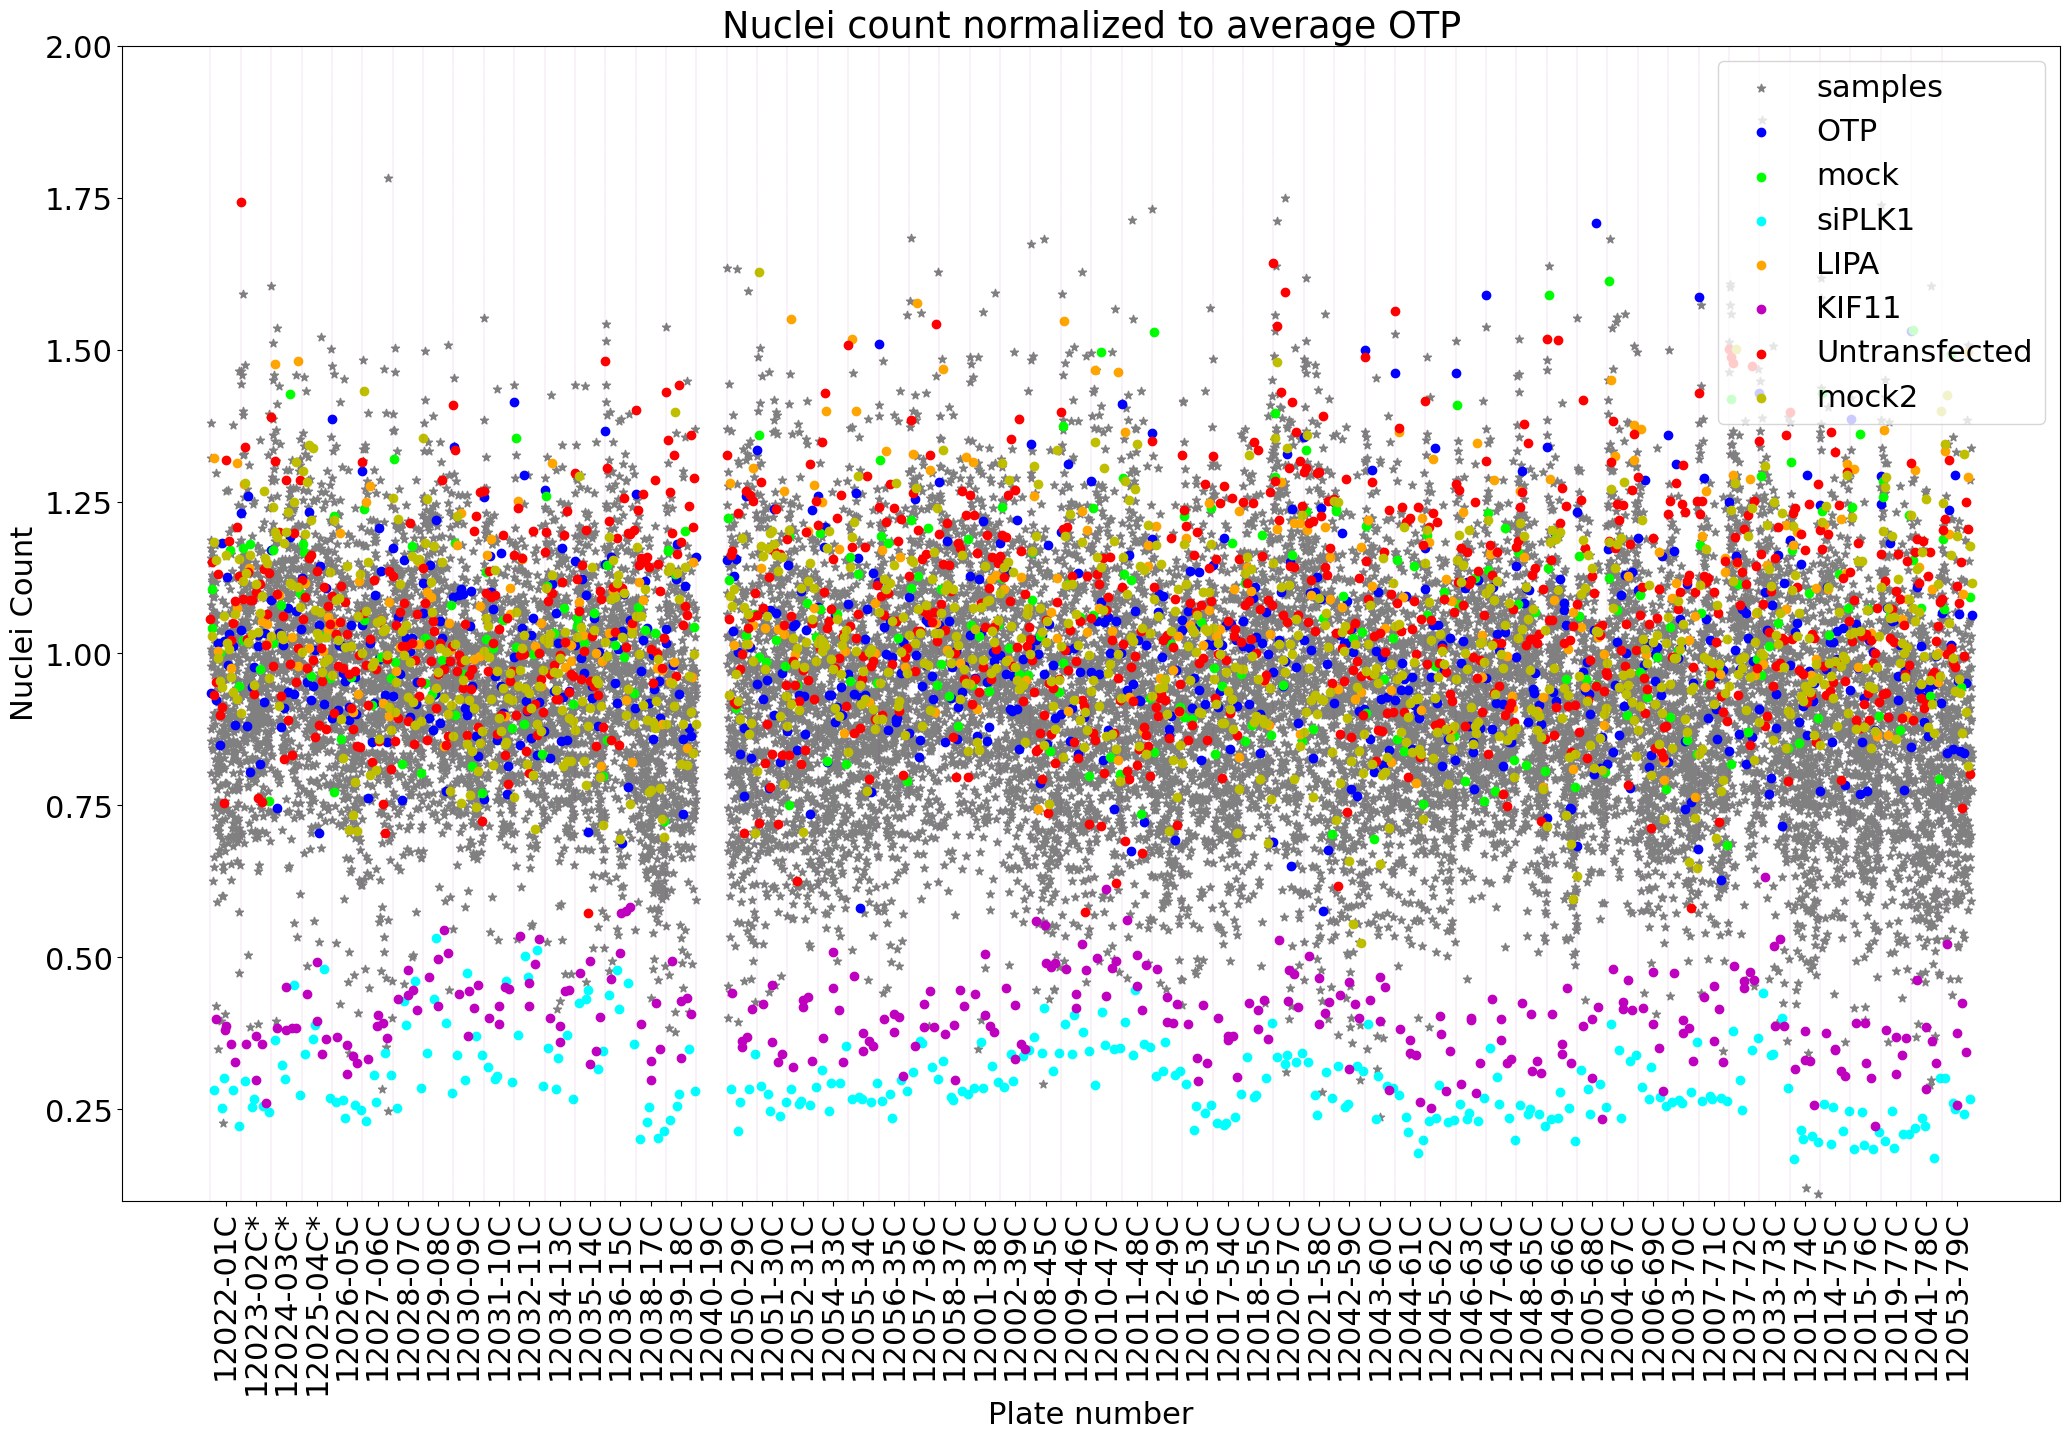

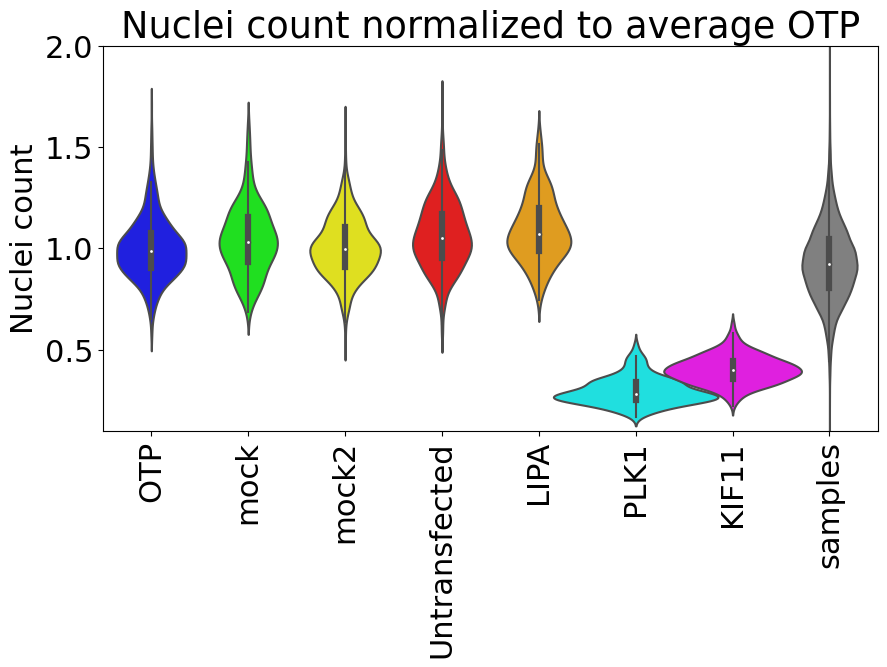

In [12]:
#COPY
# Reads saved json files

#import json so you dont have to run above cell if no new files needs saving
import json
import numpy as np
import os

#make all jsonfiles into keys


#create empty list
l = []
mock_well = []
OTP_well  = []
KIF11_well =[]
LIPA_well = []
PLK1_well = []
mock2_well= []
untr_well = []
label_X = []
all_plate_well = []

#loop through all keys (jsonfiles), load, add key to the empty list l
for k in Barcode_C:
    f4 = barcode_plate.loc[barcode_plate['Barcode']==k,'4fields'].values[0]
    lb = k.split('-SA-')[1]+str((bool(f4))).replace('True','*').replace('False','')
    label_X.append(lb)
    plate_data = np.zeros([16,24])
    pl   = barcode_plate.loc[barcode_plate['Barcode']==k, 'Plate'].values[0]
   
    if len(pl) != 0:
        with open('csv_files/C/'+pl.replace('MFGTMPcx7_','')+'_count.json','r') as f:
        
        ###Normalizing to avg of OTP wells
            json_str   = json.load(f)
            json_dict  = json.loads(json_str)
            plate_data = np.array(json_dict['data'])
             ##OTP


            ## This whole part is for adding 4 more field##
            P_ID  = pl
           
            ff =barcode_plate.loc[barcode_plate['Plate']==P_ID, '4fields'].values[0]
            fourfields = 'csv_files/C/4field/'+ff.replace('MFGTMPcx7_','')+'_count.json'
            if os.path.exists(fourfields):
                with open(fourfields,'r') as f:
                    second_json_4fields = json.load(f)
                    second_json_dict_4fields = json.loads(second_json_4fields)


                    second_plate_data = np.array(second_json_dict_4fields['data'])
                    plate_data = (plate_data+second_plate_data)*0.8


    OTP_per_plate =plate_data *np.array(OTP)
    otp_avg =  OTP_per_plate[np.nonzero(OTP_per_plate)].mean()
    plate_data = plate_data/otp_avg


    ##samples
    l.append(plate_data*np.array(samples))

    ##controls
    mock_well.append(plate_data*np.array(mock))
    OTP_well.append(plate_data*np.array(OTP))
    KIF11_well.append(plate_data*np.array(KIF11))
    LIPA_well.append(plate_data*np.array(LIPA))
    PLK1_well.append(plate_data*np.array(PLK1))
    mock2_well.append(plate_data*np.array(mock2))
    untr_well.append(plate_data*np.array(untr))

    all_plate_well.append(plate_data)
      
            

          
    

#label_X= plateNr
print(len(label_X))
       
#make list into array
array_all_plates = np.array(l)
mock_plates = np.array(mock_well)
OTP_plates = np.array(OTP_well)
KIF11_plates = np.array(KIF11_well)
LIPA_plates = np.array(LIPA_well)
PLK1_plates = np.array(PLK1_well)
untr_plates = np.array(untr_well)
mock2_plates = np.array(mock2_well)


all_plates = np.array(all_plate_well)


num_of_plates = len(Barcode_C)


all_for_plot = np.zeros([1,num_of_plates*384])
mock_for_plot = np.zeros([1,num_of_plates*384])
OTP_for_plot = np.zeros([1,num_of_plates*384])
KIF11_for_plot = np.zeros([1,num_of_plates*384])
LIPA_for_plot = np.zeros([1,num_of_plates*384])
PLK1_for_plot = np.zeros([1,num_of_plates*384])
untr_for_plot = np.zeros([1,num_of_plates*384])
mock2_for_plot = np.zeros([1,num_of_plates*384])

all_plate_for_plot = np.zeros([1,num_of_plates*384])

for plate_n in range(num_of_plates):
    wells = np.reshape(array_all_plates[plate_n,:,:],(1,384))
    all_for_plot[0,plate_n*384:(plate_n+1)*(384)]= wells

    mock_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(mock_plates[plate_n,:,:],(1,384))
    OTP_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(OTP_plates[plate_n,:,:],(1,384))
    KIF11_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(KIF11_plates[plate_n,:,:],(1,384))
    LIPA_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(LIPA_plates[plate_n,:,:],(1,384))
    PLK1_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(PLK1_plates[plate_n,:,:],(1,384))
    untr_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(untr_plates[plate_n,:,:],(1,384))
    mock2_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(mock2_plates[plate_n,:,:],(1,384))
    
    all_plate_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(all_plates[plate_n,:,:],(1,384)) 
    

#fig = plt.figure(figsize=(15,20))
#ax1 = fig.add_axes([0.1, 0.1, 0.8, 0.8]) # main axes

fig, ax1 = plt.subplots(1,1,figsize=(25,15))



plt.scatter(np.arange(all_for_plot.shape[1]),all_for_plot[0],color='gray',marker='*')

plt.scatter(np.arange((OTP_for_plot.shape[1])),OTP_for_plot,color='blue')
plt.scatter(np.arange((mock_for_plot.shape[1])),mock_for_plot,color='lime')

plt.scatter(np.arange((PLK1_for_plot.shape[1])),PLK1_for_plot,color ='cyan')

plt.scatter(np.arange((LIPA_for_plot.shape[1])),LIPA_for_plot,color='orange')
plt.scatter(np.arange((KIF11_for_plot.shape[1])),KIF11_for_plot,color='m')

plt.scatter(np.arange((untr_for_plot.shape[1])),untr_for_plot,color='r')

plt.scatter(np.arange((mock2_for_plot.shape[1])),mock2_for_plot,color='y')


X      = np.arange(num_of_plates)*384

plt.vlines(x=X,ymin=0,ymax=40000,colors='purple', ls='--', lw=0.1)


ax1.set_xticks(X+192)

ax1.set_xticklabels(label_X, rotation=90)
plt.xlabel('Plate number')
plt.ylabel('Nuclei Count')
plt.rcParams.update({'font.size': 22})
plt.ylim([0.1,2])
plt.legend(['samples','OTP','mock','siPLK1','LIPA','KIF11','Untransfected','mock2'])
plt.title('Nuclei count normalized to average OTP')


fig, ax2 = plt.subplots(1,1,figsize=(10,5))

sns.violinplot([OTP_for_plot[OTP_for_plot>0],mock_for_plot[mock_for_plot>0],
                mock2_for_plot[mock2_for_plot>0],untr_for_plot[untr_for_plot>0],LIPA_for_plot[LIPA_for_plot>0],
                PLK1_for_plot[PLK1_for_plot>0],
                KIF11_for_plot[KIF11_for_plot>0],all_for_plot[all_for_plot>0]],
                palette=['blue','lime','yellow','red','orange','cyan','magenta','gray'],width=1.7)
label_X = ['OTP','mock','mock2','Untransfected','LIPA','PLK1','KIF11','samples']
ax2.set_xticklabels(label_X, rotation=90)

plt.ylim([0.1,2])

plt.ylabel('Nuclei count')
plt.title('Nuclei count normalized to average OTP')

np.save('C_normalized_count.npy',all_plate_for_plot,allow_pickle=True)


### Combine Nuclei count with four fields

In the following cells we first merge main plates with 4 field plates and then normalize them

In [14]:
plateNr = !ls csv_files/C/*.csv  | sed s/'.csv'/''/g 
plateNr

['csv_files/C/MFGTMPcx7_170521220001',
 'csv_files/C/MFGTMPcx7_170522170001',
 'csv_files/C/MFGTMPcx7_170523120001',
 'csv_files/C/MFGTMPcx7_170525050001',
 'csv_files/C/MFGTMPcx7_170526040001',
 'csv_files/C/MFGTMPcx7_170526230001',
 'csv_files/C/MFGTMPcx7_170527180001',
 'csv_files/C/MFGTMPcx7_170528130001',
 'csv_files/C/MFGTMPcx7_170529220001',
 'csv_files/C/MFGTMPcx7_170530190001',
 'csv_files/C/MFGTMPcx7_170531150001',
 'csv_files/C/MFGTMPcx7_170602060001',
 'csv_files/C/MFGTMPcx7_170603010001',
 'csv_files/C/MFGTMPcx7_170606000001',
 'csv_files/C/MFGTMPcx7_170607150001',
 'csv_files/C/MFGTMPcx7_170608210001',
 'csv_files/C/MFGTMPcx7_170618140001',
 'csv_files/C/MFGTMPcx7_170619100001',
 'csv_files/C/MFGTMPcx7_170620050001',
 'csv_files/C/MFGTMPcx7_170621200001',
 'csv_files/C/MFGTMPcx7_170622150001',
 'csv_files/C/MFGTMPcx7_170623110001',
 'csv_files/C/MFGTMPcx7_170624060001',
 'csv_files/C/MFGTMPcx7_170625010001',
 'csv_files/C/MFGTMPcx7_170625200001',
 'csv_files/C/MFGTMPcx7_1

#### The following cell is for creating _combined_area from combined .csv files of main plates with 4 fields
## DO not run it if you already have _combined_4fields.json files

In [15]:
#COPY for cell mean area
row_number = ['A','B','C','D','E','F','G','H','I','J','K','L','M','N','O','P']
column_number = ['01','02','03','04','05','06','07','08','09','10','11','12','13','14','15','16','17','18','19','20','21','22','23','24']

#Create empty list
my_dict_cellSize = {}

# Access the value using the key
#my_dict_cellSize["MFGTMPcx7_170524210001"] 
for p in plateNr:
    temp_df_size = pd.read_csv(p+'.csv')
    P_ID   = p.split('/C/')[1]
    print(P_ID)
    
    fourfields =barcode_plate.loc[barcode_plate['Plate']==P_ID, '4fields'].values[0]
    
    
    if len(fourfields):
        print(fourfields,'yesss')
        second_df  = pd.read_csv('csv_files/C/4field/'+fourfields+'.csv')
        merged_df_size = pd.concat([temp_df_size, second_df], axis=0)
            
        temp_df_size = merged_df_size         
    
   
    new_df_cell_mean_area = pd.DataFrame(columns=column_number,index=row_number)
    for r in row_number:
        for c in column_number:
            well = r+c
            new_df_cell_mean_area.loc[r][c] = np.mean(temp_df_size[temp_df_size['Image_name'].str.contains('_'+well)]['Area']) #switched pattern to well
    my_dict_cellSize[p]=new_df_cell_mean_area


MFGTMPcx7_170521220001
MFGTMPcx7_170720000001 yesss
MFGTMPcx7_170522170001
MFGTMPcx7_170720060001 yesss
MFGTMPcx7_170523120001
MFGTMPcx7_170720110001 yesss
MFGTMPcx7_170525050001
MFGTMPcx7_170526040001
MFGTMPcx7_170526230001
MFGTMPcx7_170527180001
MFGTMPcx7_170528130001
MFGTMPcx7_170529220001
MFGTMPcx7_170530190001
MFGTMPcx7_170531150001
MFGTMPcx7_170602060001
MFGTMPcx7_170603010001
MFGTMPcx7_170606000001
MFGTMPcx7_170607150001
MFGTMPcx7_170608210001
MFGTMPcx7_170618140001
MFGTMPcx7_170619100001
MFGTMPcx7_170620050001
MFGTMPcx7_170621200001
MFGTMPcx7_170622150001
MFGTMPcx7_170623110001
MFGTMPcx7_170624060001
MFGTMPcx7_170625010001
MFGTMPcx7_170625200001
MFGTMPcx7_170626150001
MFGTMPcx7_170702050001
MFGTMPcx7_170703000001
MFGTMPcx7_170703220001
MFGTMPcx7_170704170001
MFGTMPcx7_170706100001
MFGTMPcx7_170709030001
MFGTMPcx7_170709220001
MFGTMPcx7_170710180001
MFGTMPcx7_170712100001
MFGTMPcx7_170713140001
MFGTMPcx7_170714100001
MFGTMPcx7_170715070001
MFGTMPcx7_170716020001
MFGTMPcx7_170716

In [16]:
# Saves dictionaries in json files, remove names of plates you already have jsons for in cell above before running
import json
for k in my_dict_cellSize.keys():
    json.dump(my_dict_cellSize[k].to_json(orient='split'), open(k.replace('MFGTMPcx7_','')+'_area_combined_4fields.json', 'w'))

### Normalize and merge 4fields for those plates that has 4 more fields for object area

In [17]:
Barcode_C    = [ba for ba in barcode_plate['Barcode'] if ba.endswith('C')]
Barcode_C  


['20170516-SA-12022-01C',
 '20170516-SA-12023-02C',
 '20170516-SA-12024-03C',
 '20170516-SA-12025-04C',
 '20170522-SA-12026-05C',
 '20170522-SA-12027-06C',
 '20170522-SA-12028-07C',
 '20170522-SA-12029-08C',
 '20170523-SA-12030-09C',
 '20170523-SA-12031-10C',
 '20170523-SA-12032-11C',
 '20170529-SA-12034-13C',
 '20170529-SA-12035-14C',
 '20170529-SA-12036-15C',
 '20170530-SA-12038-17C',
 '20170530-SA-12039-18C',
 '20170530-SA-12040-19C',
 '20170613-SA-12050-29C',
 '20170613-SA-12051-30C',
 '20170613-SA-12052-31C',
 '20170614-SA-12054-33C',
 '20170614-SA-12055-34C',
 '20170614-SA-12056-35C',
 '20170614-SA-12057-36C',
 '20170619-SA-12058-37C',
 '20170619-SA-12001-38C',
 '20170619-SA-12002-39C',
 '20170626-SA-12008-45C',
 '20170626-SA-12009-46C',
 '20170626-SA-12010-47C',
 '20170626-SA-12011-48C',
 '20170627-SA-12012-49C',
 '20170703-SA-12016-53C',
 '20170703-SA-12017-54C',
 '20170703-SA-12018-55C',
 '20170704-SA-12020-57C',
 '20170704-SA-12021-58C',
 '20170704-SA-12042-59C',
 '20170704-S

1747.9143988128087
1722.0763871212666
1738.0194392092917
1742.5082891707832
1723.7170288348332
1724.4291332629416
1712.0761059590502
1699.7411364109166
1755.225637902625
1731.1406551328503
1711.3186951630003
1710.5832846530914
1731.350223288792
1703.6846643056833
1724.2263909895835
1721.0049246080998
nan
1724.3295508316585
1710.1933653489168
1685.7868293374586
1702.6855347033086
1686.3727175785
1704.6079091311
1714.5637533515335
1703.33175942795
1693.9051724648168
1678.5758423375999
1797.8304230869162
1821.5631543920001
1795.8904660884502
1837.1777264002833


C:\Users\salma\AppData\Local\Temp\ipykernel_28316\1435822074.py:43: RuntimeWarning: Mean of empty slice.
  otp_avg =  OTP_per_plate[np.nonzero(OTP_per_plate)].mean()
C:\Users\salma\.conda\envs\SalmaEnv\lib\site-packages\numpy\core\_methods.py:190: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)


1783.4699460172167
1677.8348858149502
1676.0780828171248
1700.4483138526837
1712.3559639805082
1683.9547294823335
1714.8550684737336
1708.5102653909917
1687.490700089975
1695.0520653345166
1690.2093824967417
1679.7952547127163
1702.0998761364917
1736.7069159637165
2339.073184543808
1804.2891857744082
1761.5495689204083
1754.1443447299582
1759.2019558299332
1782.9905192691997
1796.627271634725
1683.4489457930583
1671.7224810783753
1664.4949108073833
1687.7760744325417
1679.3925407648749
1688.5998939690835


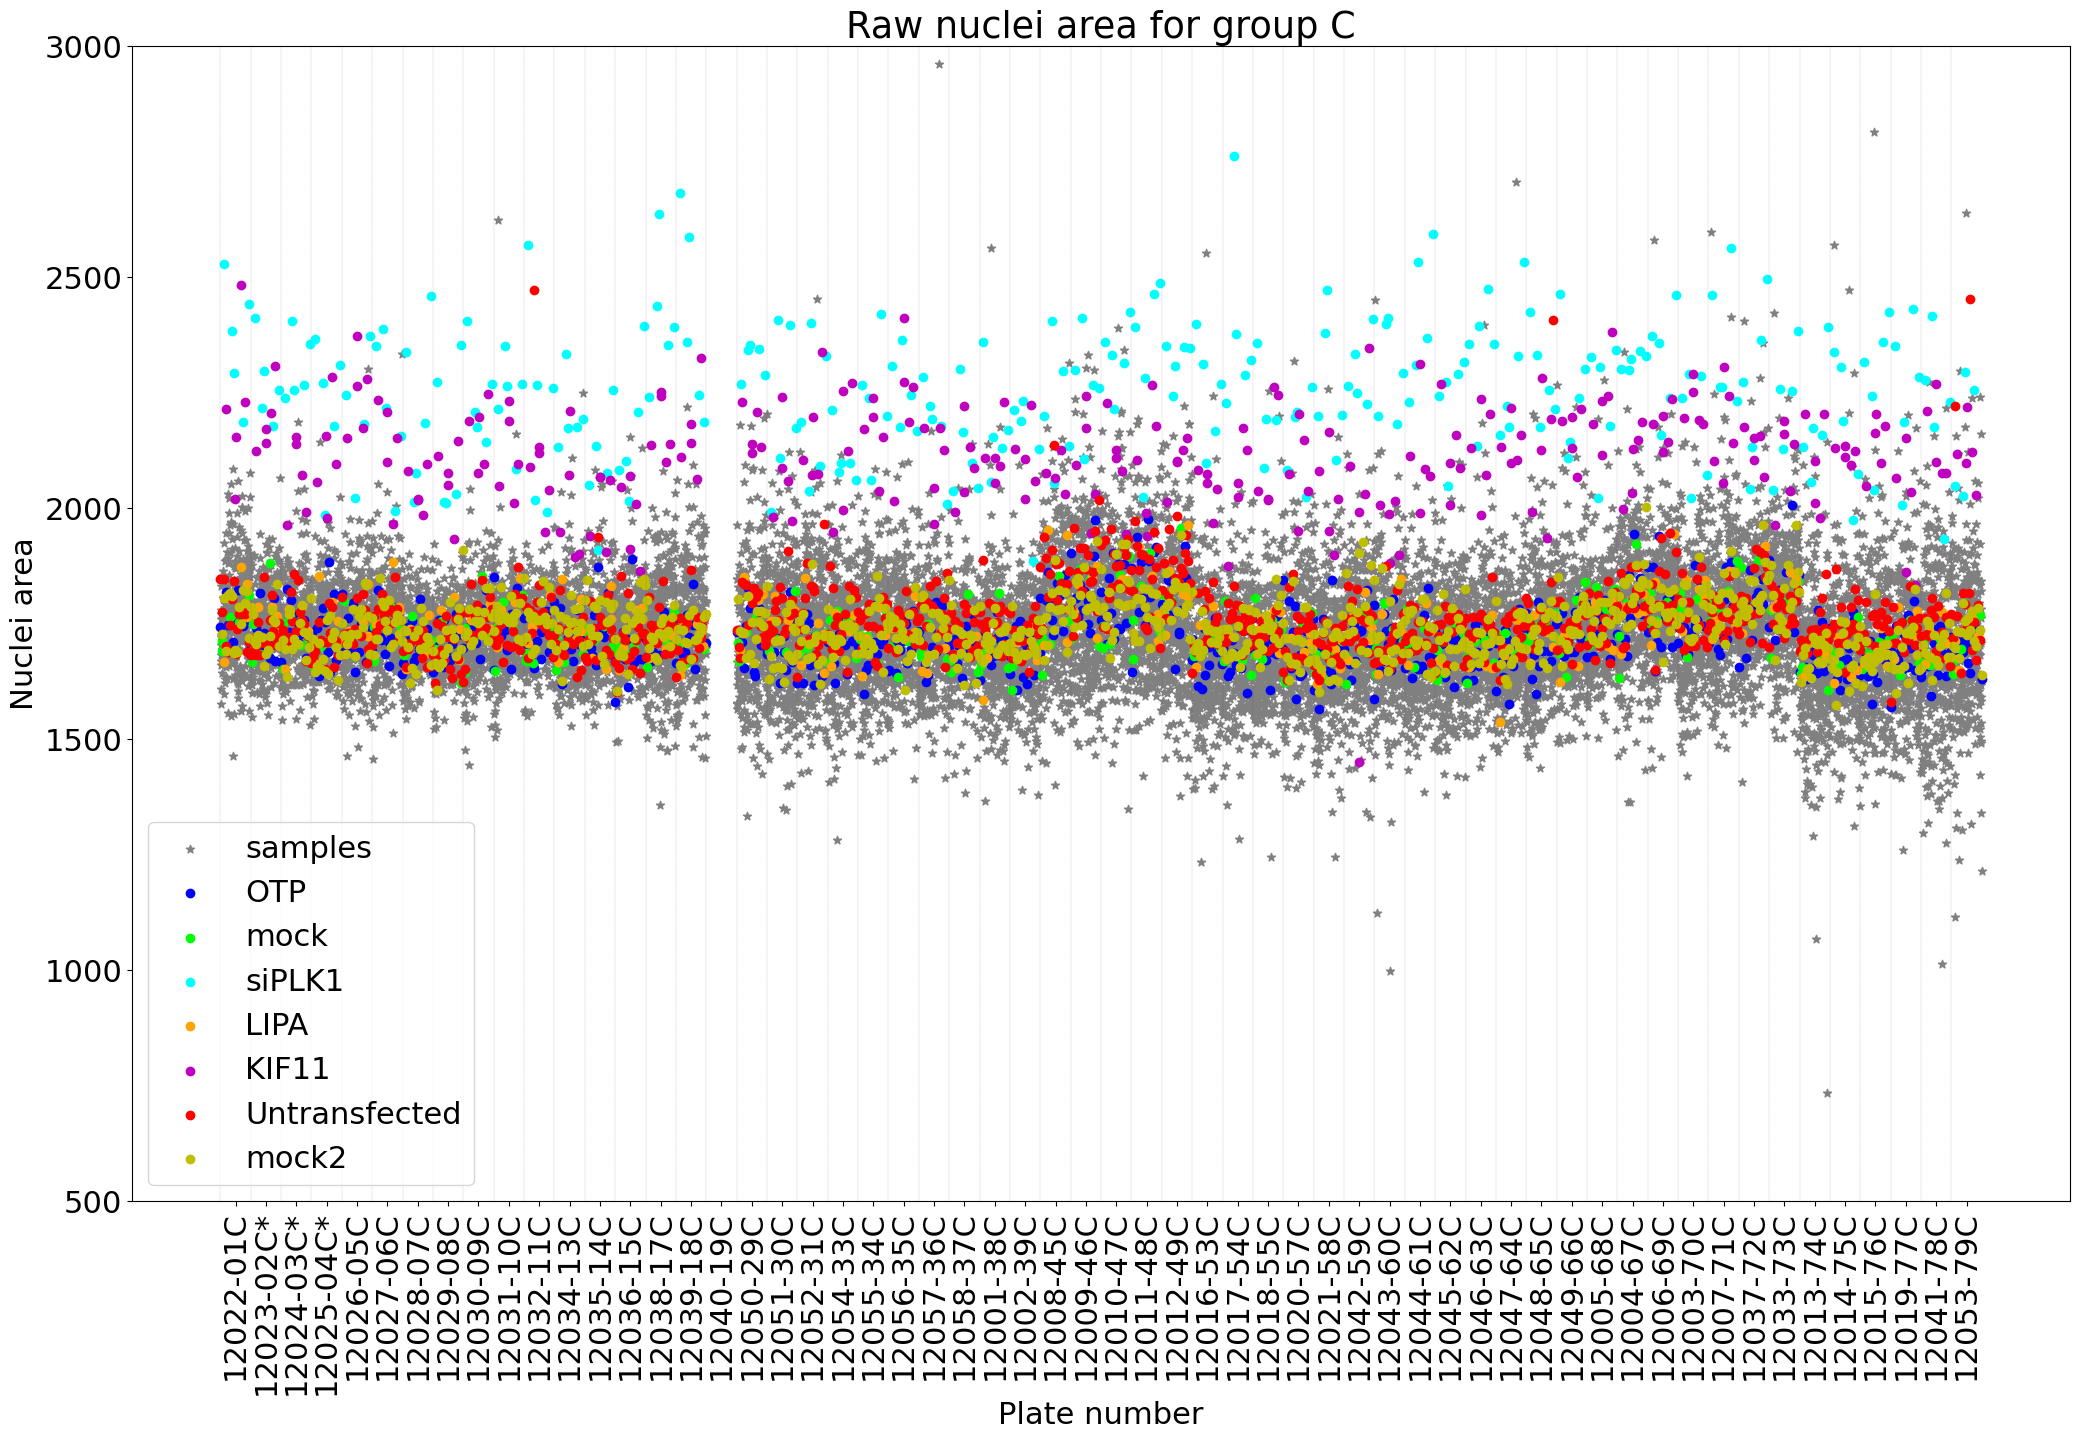

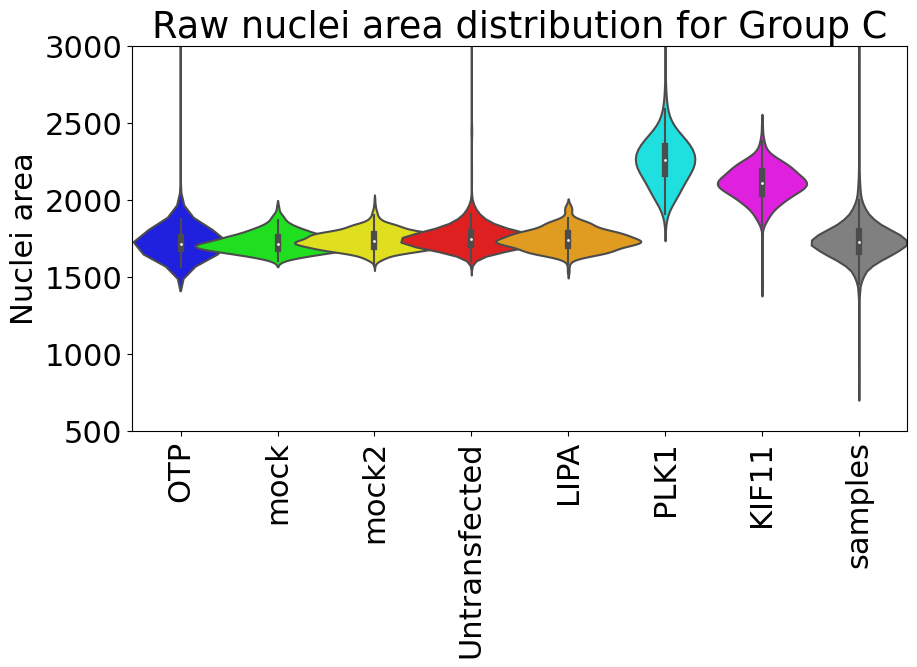

In [19]:
# Reads saved json files

#import json so you dont have to run above cell if no new files needs saving
import json
import numpy as np

#make all jsonfiles into keys



#create empty list
l = []
mock_well = []
OTP_well  = []
KIF11_well =[]
LIPA_well = []
PLK1_well = []
mock2_well= []
untr_well = []
label_X = []
all_plate_well = []

#loop through all keys (jsonfiles), load, add key to the empty list l
for k in Barcode_C:
            
    f4 = barcode_plate.loc[barcode_plate['Barcode']==k,'4fields'].values[0]
    lb = k.split('-SA-')[1]+str((bool(f4))).replace('True','*').replace('False','')
    label_X.append(lb)
    
    plate_data = np.zeros([16,24])
    pl   = barcode_plate.loc[barcode_plate['Barcode']==k, 'Plate'].values[0]
   
    if len(pl) != 0:
        with open('csv_files/C/'+pl.replace('MFGTMPcx7_','')+'_area_combined_4fields.json','r') as f:
        
            json_str = json.load(f)
            json_dict = json.loads(json_str)
            plate_data = np.array(json_dict['data'])
        
         ##OTP

    OTP_per_plate =plate_data *np.array(OTP)
    otp_avg =  OTP_per_plate[np.nonzero(OTP_per_plate)].mean()
    print(otp_avg)
    #plate_data = plate_data/otp_avg


    ##samples
    l.append(plate_data*np.array(samples))

    ##controls
    mock_well.append(plate_data*np.array(mock))
    OTP_well.append(plate_data*np.array(OTP))
    KIF11_well.append(plate_data*np.array(KIF11))
    LIPA_well.append(plate_data*np.array(LIPA))
    PLK1_well.append(plate_data*np.array(PLK1))
    mock2_well.append(plate_data*np.array(mock2))
    untr_well.append(plate_data*np.array(untr))

    all_plate_well.append(plate_data)

        
       
#make list into array
array_all_plates = np.array(l)
mock_plates = np.array(mock_well)
OTP_plates = np.array(OTP_well)
KIF11_plates = np.array(KIF11_well)
LIPA_plates = np.array(LIPA_well)
PLK1_plates = np.array(PLK1_well)
untr_plates = np.array(untr_well)
mock2_plates = np.array(mock2_well)


all_plates = np.array(all_plate_well)


num_of_plates = len(Barcode_C)


all_for_plot = np.zeros([1,num_of_plates*384])
mock_for_plot = np.zeros([1,num_of_plates*384])
OTP_for_plot = np.zeros([1,num_of_plates*384])
KIF11_for_plot = np.zeros([1,num_of_plates*384])
LIPA_for_plot = np.zeros([1,num_of_plates*384])
PLK1_for_plot = np.zeros([1,num_of_plates*384])
untr_for_plot = np.zeros([1,num_of_plates*384])
mock2_for_plot = np.zeros([1,num_of_plates*384])

all_plate_for_plot = np.zeros([1,num_of_plates*384])

for plate_n in range(num_of_plates):
    wells = np.reshape(array_all_plates[plate_n,:,:],(1,384))
    all_for_plot[0,plate_n*384:(plate_n+1)*(384)]= wells

    mock_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(mock_plates[plate_n,:,:],(1,384))
    OTP_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(OTP_plates[plate_n,:,:],(1,384))
    KIF11_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(KIF11_plates[plate_n,:,:],(1,384))
    LIPA_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(LIPA_plates[plate_n,:,:],(1,384))
    PLK1_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(PLK1_plates[plate_n,:,:],(1,384))
    untr_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(untr_plates[plate_n,:,:],(1,384))
    mock2_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(mock2_plates[plate_n,:,:],(1,384))
    
    all_plate_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(all_plates[plate_n,:,:],(1,384)) 
    

#fig = plt.figure(figsize=(15,20))
#ax1 = fig.add_axes([0.1, 0.1, 0.8, 0.8]) # main axes

fig, ax1 = plt.subplots(1,1,figsize=(25,15))



plt.scatter(np.arange(all_for_plot.shape[1]),all_for_plot[0],color='gray',marker='*')

plt.scatter(np.arange((OTP_for_plot.shape[1])),OTP_for_plot,color='blue')
plt.scatter(np.arange((mock_for_plot.shape[1])),mock_for_plot,color='lime')

plt.scatter(np.arange((PLK1_for_plot.shape[1])),PLK1_for_plot,color ='cyan')

plt.scatter(np.arange((LIPA_for_plot.shape[1])),LIPA_for_plot,color='orange')
plt.scatter(np.arange((KIF11_for_plot.shape[1])),KIF11_for_plot,color='m')

plt.scatter(np.arange((untr_for_plot.shape[1])),untr_for_plot,color='r')

plt.scatter(np.arange((mock2_for_plot.shape[1])),mock2_for_plot,color='y')

X      = np.arange(num_of_plates)*384

plt.vlines(x=X,ymin=0,ymax=40000,colors='purple', ls='--', lw=0.1)


#for k in keys_json:
    #label_X.append(k.replace('_count.json','').replace('CSV/A/',''))
#for k in Barcode:
#    label_X.append(k)
    

#label_X= plateNr
#print(len(label_X))
ax1.set_xticks(X+192)

ax1.set_xticklabels(label_X, rotation=90)
plt.xlabel('Plate number')
plt.ylabel('Nuclei area')
plt.rcParams.update({'font.size': 22})
plt.ylim([500,3000])
plt.legend(['samples','OTP','mock','siPLK1','LIPA','KIF11','Untransfected','mock2'])
plt.title('Raw nuclei area for group C')


fig, ax2 = plt.subplots(1,1,figsize=(10,5))

sns.violinplot([OTP_for_plot[OTP_for_plot>0],mock_for_plot[mock_for_plot>0],
                mock2_for_plot[mock2_for_plot>0],untr_for_plot[untr_for_plot>0],LIPA_for_plot[LIPA_for_plot>0],
                PLK1_for_plot[PLK1_for_plot>0],
                KIF11_for_plot[KIF11_for_plot>0],all_for_plot[all_for_plot>0]],
                palette=['blue','lime','yellow','red','orange','cyan','magenta','gray'],width=1.7)
label_X = ['OTP','mock','mock2','Untransfected','LIPA','PLK1','KIF11','samples']
ax2.set_xticklabels(label_X, rotation=90)
plt.ylabel('Nuclei area')
plt.title('Raw nuclei area distribution for Group C')
plt.ylim([500,3000])


np.save('C_area.npy',all_plate_for_plot,allow_pickle=True)

1747.9143988128087
1722.0763871212666
1738.0194392092917
1742.5082891707832
1723.7170288348332
1724.4291332629416
1712.0761059590502
1699.7411364109166
1755.225637902625
1731.1406551328503
1711.3186951630003
1710.5832846530914
1731.350223288792
1703.6846643056833
1724.2263909895835
1721.0049246080998
nan
1724.3295508316585
1710.1933653489168
1685.7868293374586
1702.6855347033086
1686.3727175785
1704.6079091311
1714.5637533515335
1703.33175942795
1693.9051724648168
1678.5758423375999
1797.8304230869162
1821.5631543920001
1795.8904660884502
1837.1777264002833
1783.4699460172167
1677.8348858149502
1676.0780828171248
1700.4483138526837
1712.3559639805082
1683.9547294823335
1714.8550684737336
1708.5102653909917
1687.490700089975
1695.0520653345166
1690.2093824967417
1679.7952547127163
1702.0998761364917
1736.7069159637165
2339.073184543808
1804.2891857744082
1761.5495689204083
1754.1443447299582
1759.2019558299332
1782.9905192691997
1796.627271634725
1683.4489457930583
1671.7224810783753
16

C:\Users\salma\AppData\Local\Temp\ipykernel_28316\3104871887.py:47: RuntimeWarning: Mean of empty slice.
  otp_avg =  OTP_per_plate[np.nonzero(OTP_per_plate)].mean()


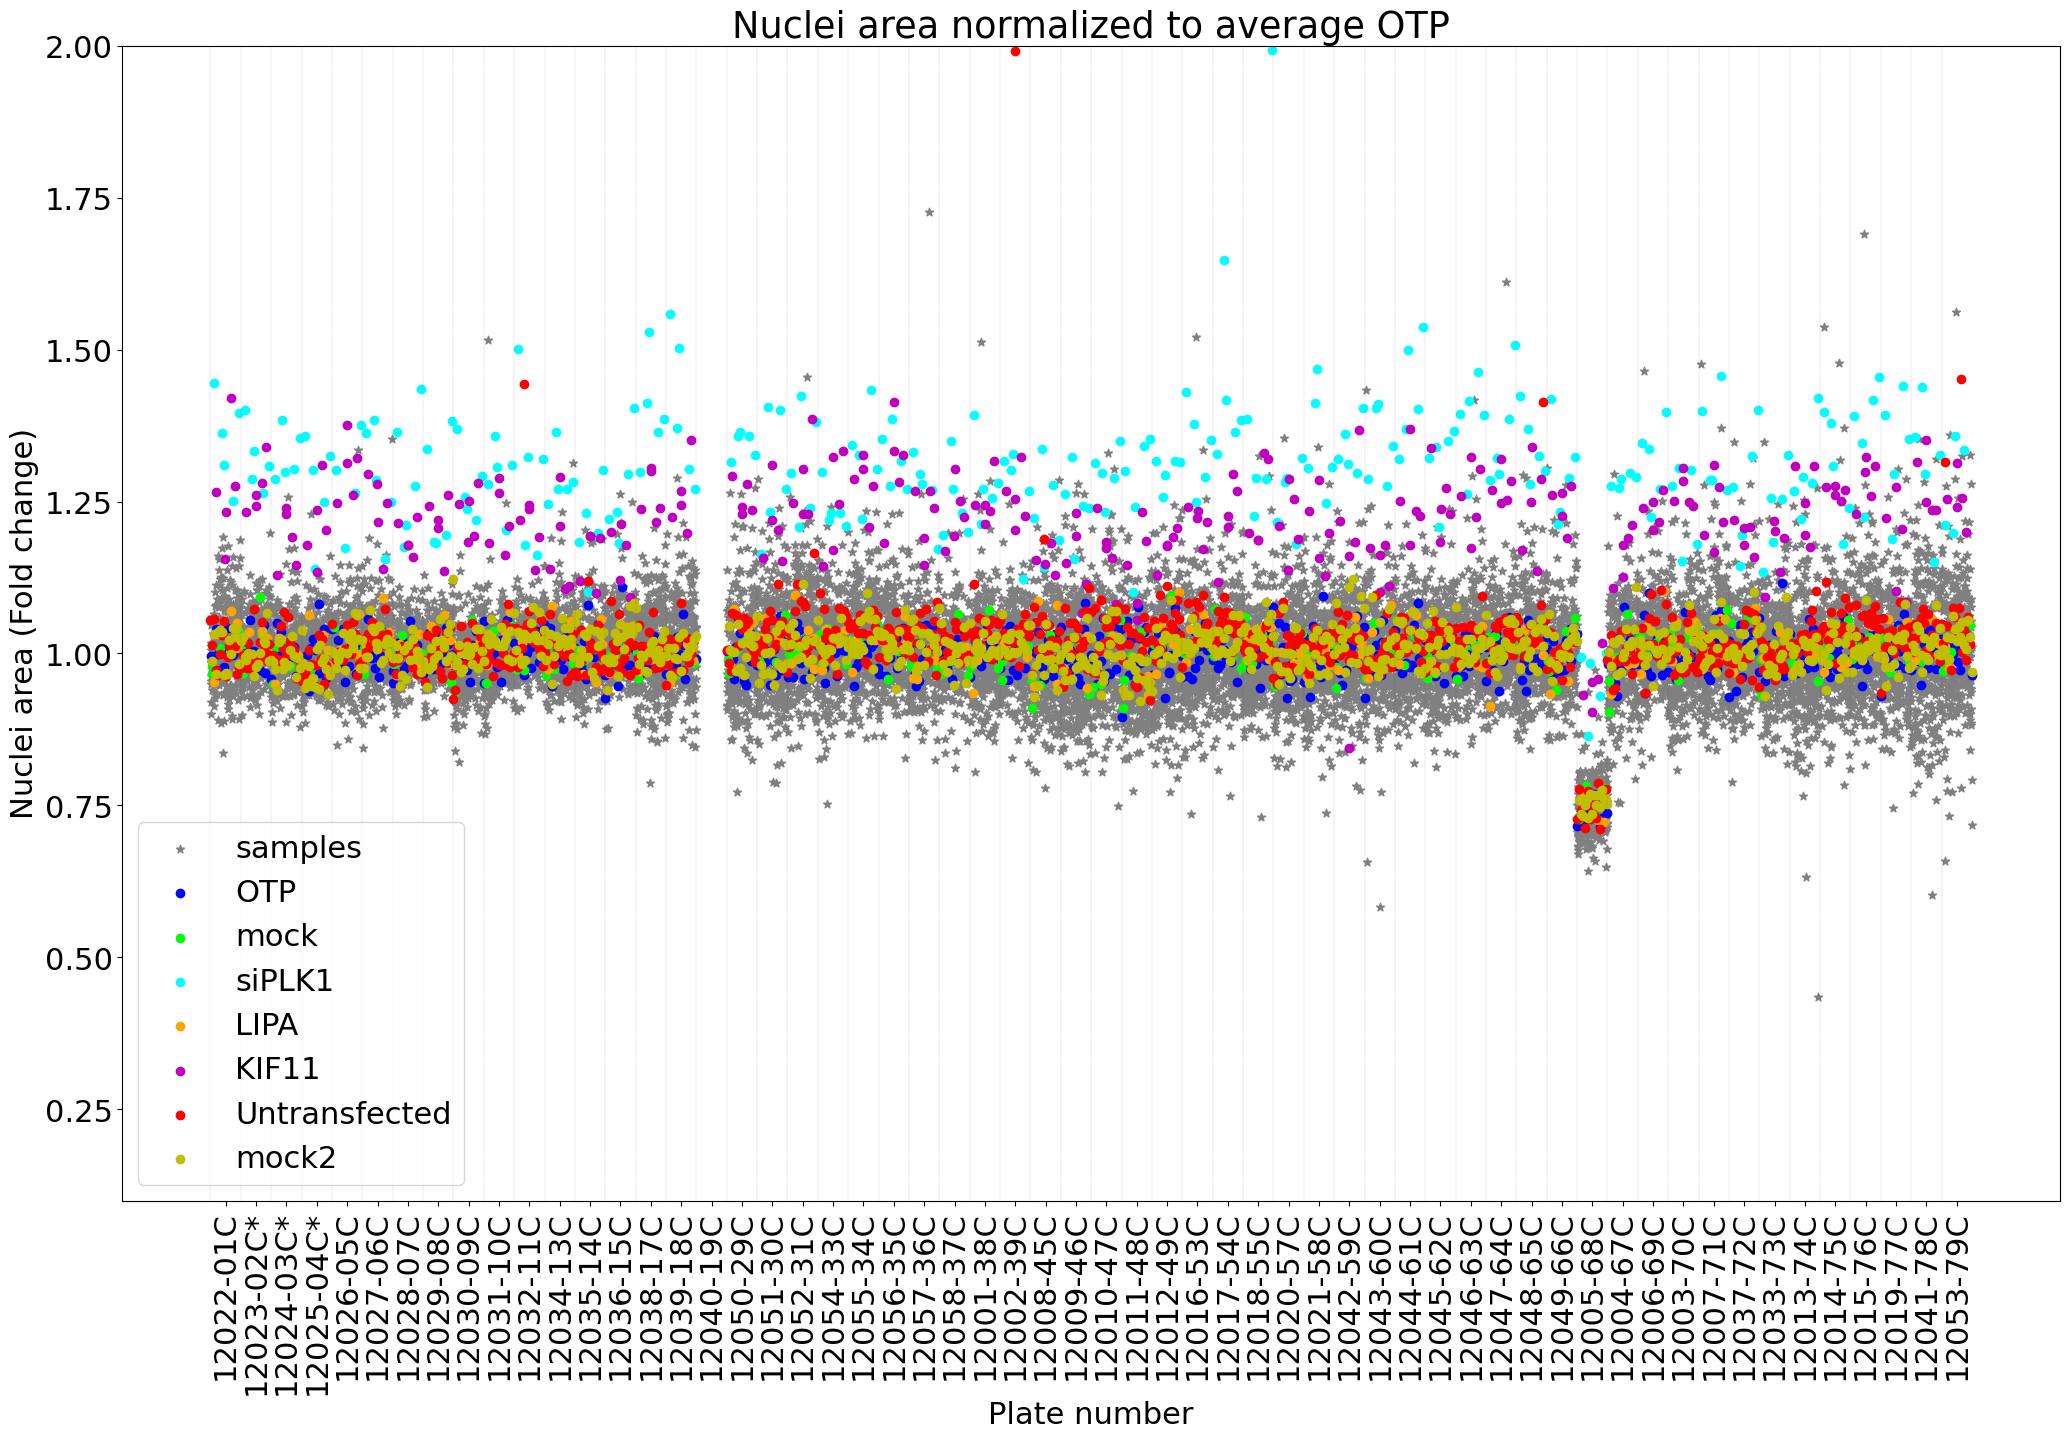

In [21]:

#COPY
# Reads saved json files

#import json so you dont have to run above cell if no new files needs saving
import json
import numpy as np

#make all jsonfiles into keys


#create empty list
l = []
mock_well = []
OTP_well  = []
KIF11_well =[]
LIPA_well = []
PLK1_well = []
mock2_well= []
untr_well = []

all_plate_well = []

#loop through all keys (jsonfiles), load, add key to the empty list l
for k in Barcode_C:
            
    f4 = barcode_plate.loc[barcode_plate['Barcode']==k,'4fields'].values[0]
    lb = k.split('-SA-')[1]+str((bool(f4))).replace('True','*').replace('False','')
    label_X.append(lb)
    
    plate_data = np.zeros([16,24])
    pl   = barcode_plate.loc[barcode_plate['Barcode']==k, 'Plate'].values[0]
   
    if len(pl) != 0:
        with open('csv_files/C/'+pl.replace('MFGTMPcx7_','')+'_area_combined_4fields.json','r') as f:
        
       
        
            json_str = json.load(f)
            json_dict = json.loads(json_str)
            plate_data = np.array(json_dict['data'])
        
        
        
         ##OTP

    OTP_per_plate =plate_data *np.array(OTP)
    otp_avg =  OTP_per_plate[np.nonzero(OTP_per_plate)].mean()
    print(otp_avg)
    plate_data = plate_data/otp_avg


    ##samples
    l.append(plate_data*np.array(samples))

    ##controls
    mock_well.append(plate_data*np.array(mock))
    OTP_well.append(plate_data*np.array(OTP))
    KIF11_well.append(plate_data*np.array(KIF11))
    LIPA_well.append(plate_data*np.array(LIPA))
    PLK1_well.append(plate_data*np.array(PLK1))
    mock2_well.append(plate_data*np.array(mock2))
    untr_well.append(plate_data*np.array(untr))

    all_plate_well.append(plate_data)


       
#make list into array
array_all_plates = np.array(l)
mock_plates = np.array(mock_well)
OTP_plates = np.array(OTP_well)
KIF11_plates = np.array(KIF11_well)
LIPA_plates = np.array(LIPA_well)
PLK1_plates = np.array(PLK1_well)
untr_plates = np.array(untr_well)
mock2_plates = np.array(mock2_well)


all_plates = np.array(all_plate_well)


num_of_plates = len(Barcode_C)


all_for_plot = np.zeros([1,num_of_plates*384])
mock_for_plot = np.zeros([1,num_of_plates*384])
OTP_for_plot = np.zeros([1,num_of_plates*384])
KIF11_for_plot = np.zeros([1,num_of_plates*384])
LIPA_for_plot = np.zeros([1,num_of_plates*384])
PLK1_for_plot = np.zeros([1,num_of_plates*384])
untr_for_plot = np.zeros([1,num_of_plates*384])
mock2_for_plot = np.zeros([1,num_of_plates*384])

all_plate_for_plot = np.zeros([1,num_of_plates*384])

for plate_n in range(num_of_plates):
    wells = np.reshape(array_all_plates[plate_n,:,:],(1,384))
    all_for_plot[0,plate_n*384:(plate_n+1)*(384)]= wells

    mock_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(mock_plates[plate_n,:,:],(1,384))
    OTP_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(OTP_plates[plate_n,:,:],(1,384))
    KIF11_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(KIF11_plates[plate_n,:,:],(1,384))
    LIPA_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(LIPA_plates[plate_n,:,:],(1,384))
    PLK1_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(PLK1_plates[plate_n,:,:],(1,384))
    untr_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(untr_plates[plate_n,:,:],(1,384))
    mock2_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(mock2_plates[plate_n,:,:],(1,384))
    
    all_plate_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(all_plates[plate_n,:,:],(1,384)) 
    

#fig = plt.figure(figsize=(15,20))
#ax1 = fig.add_axes([0.1, 0.1, 0.8, 0.8]) # main axes

fig, ax1 = plt.subplots(1,1,figsize=(25,15))



plt.scatter(np.arange(all_for_plot.shape[1]),all_for_plot[0],color='gray',marker='*')

plt.scatter(np.arange((OTP_for_plot.shape[1])),OTP_for_plot,color='blue')
plt.scatter(np.arange((mock_for_plot.shape[1])),mock_for_plot,color='lime')

plt.scatter(np.arange((PLK1_for_plot.shape[1])),PLK1_for_plot,color ='cyan')

plt.scatter(np.arange((LIPA_for_plot.shape[1])),LIPA_for_plot,color='orange')
plt.scatter(np.arange((KIF11_for_plot.shape[1])),KIF11_for_plot,color='m')

plt.scatter(np.arange((untr_for_plot.shape[1])),untr_for_plot,color='r')

plt.scatter(np.arange((mock2_for_plot.shape[1])),mock2_for_plot,color='y')


X      = np.arange(num_of_plates)*384

plt.vlines(x=X,ymin=0,ymax=40000,colors='purple', ls='--', lw=0.1)


#for k in keys_json:
#    label_X.append(k.replace('_count.json','').replace('CSV/A/',''))
   

#label_X= plateNr
print(len(label_X))
ax1.set_xticks(X+192)

ax1.set_xticklabels(label_X, rotation=90)
plt.xlabel('Plate number')
plt.ylabel('Nuclei area (Fold change)')
plt.rcParams.update({'font.size': 22})
plt.ylim([0.1,2])
plt.legend(['samples','OTP','mock','siPLK1','LIPA','KIF11','Untransfected','mock2'])
plt.title('Nuclei area normalized to average OTP')


np.save('C_normalized_area.npy',all_plate_for_plot, allow_pickle=True)

(0.5, 1.5)

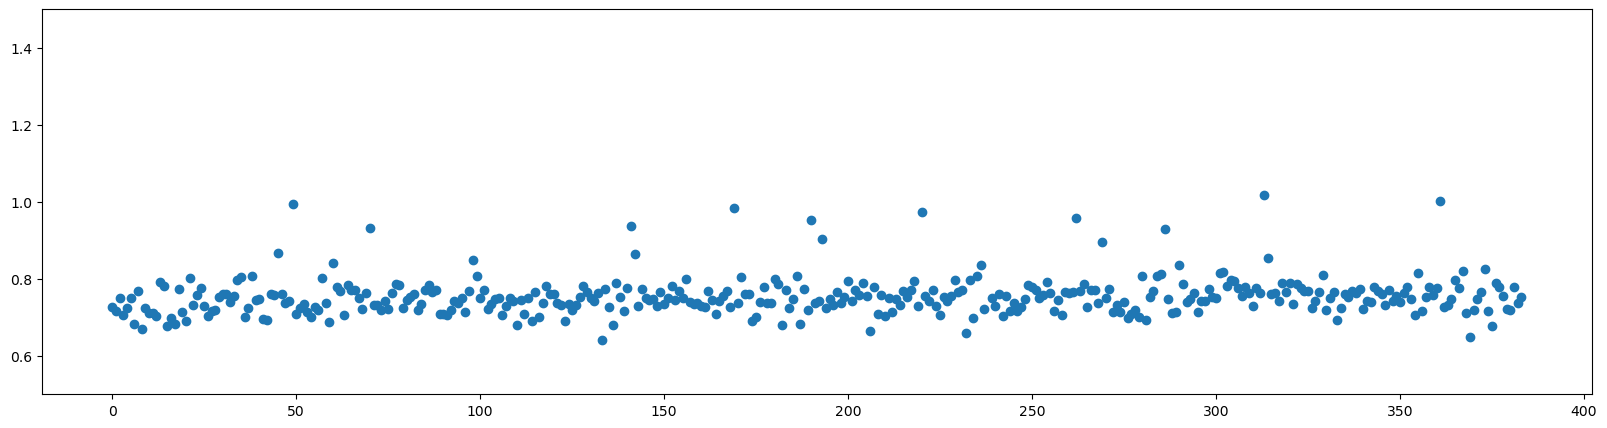

In [41]:
import numpy as np
import matplotlib.pyplot as plt

C_norm_area  = np.load('C_normalized_area.npy')
C_norm_area
X = np.arange(0,384)
plt.figure(figsize=[20,5])
plt.scatter(X,C_norm_area[0][(45*384):(46*384)])

plt.ylim([0.5,1.5])

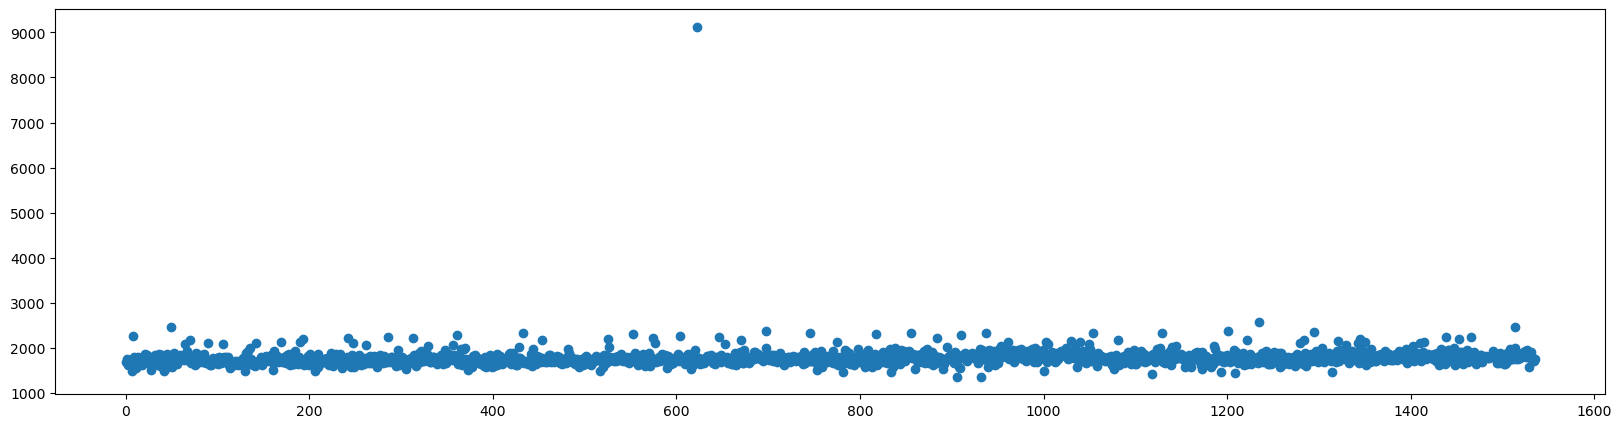

In [38]:
import numpy as np
import matplotlib.pyplot as plt

C_norm_area  = np.load('C_area.npy')
C_norm_area
X = np.arange(0,384*4)
plt.figure(figsize=[20,5])
plt.scatter(X,C_norm_area[0][(44*384):(48*384)])

#plt.ylim([0.5,1.5])

<Axes: >

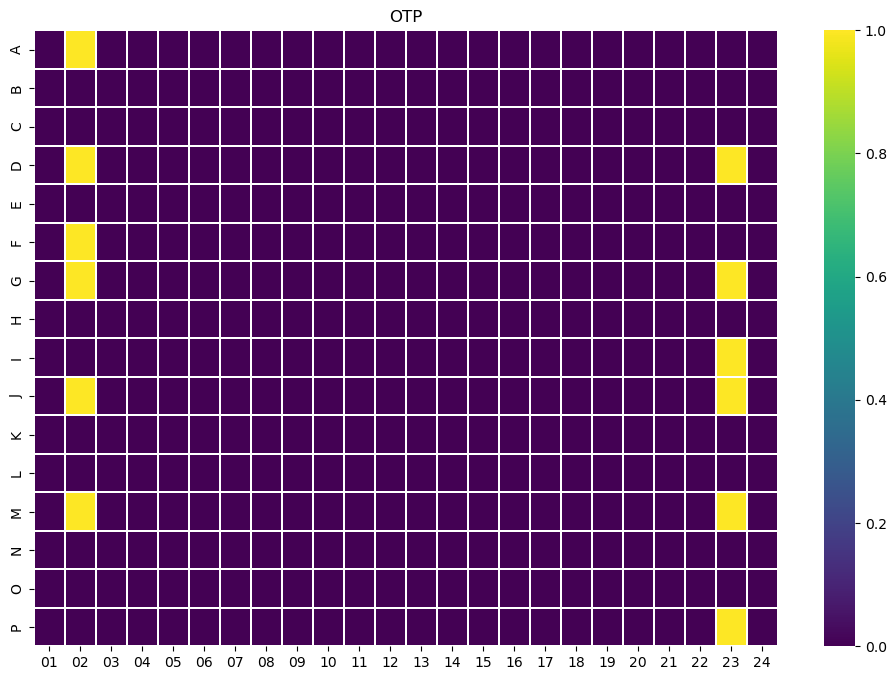

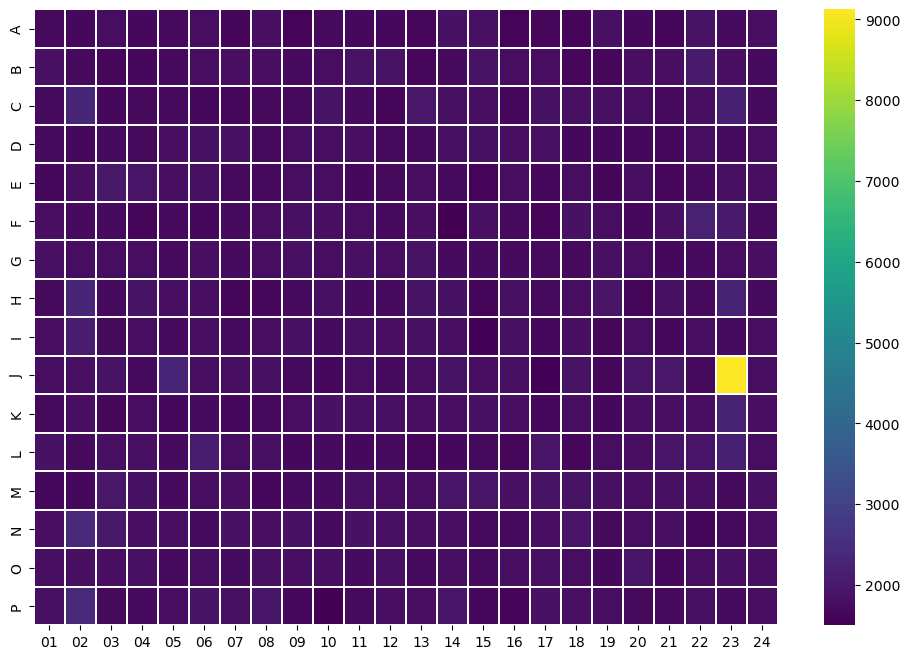

<Figure size 640x480 with 0 Axes>

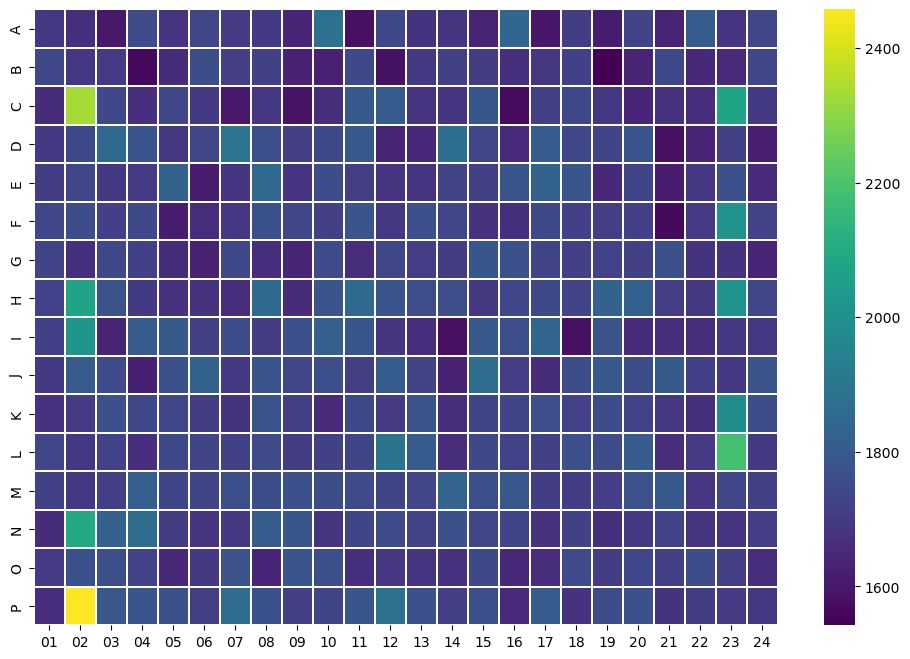

In [53]:
import pandas as pd
import json
import seaborn as sns 


import numpy as np
import pandas as pd
row_number = ['A','B','C','D','E','F','G','H','I','J','K','L','M','N','O','P']
column_number = ['01','02','03','04','05','06','07','08','09','10','11','12','13','14','15','16','17','18','19','20','21','22','23','24']


zero_data = np.zeros(shape=(16,24))
OTP = pd.DataFrame(zero_data,columns=column_number,index=row_number)
OTP_list_r = !cat control.txt | grep OTP | cut -f 1 | cut -b 1
OTP_list_c = !cat control.txt | grep OTP | cut -f 1 | cut -b 2-4
for c,r in zip(OTP_list_c,OTP_list_r):
    OTP[c][r]=1
plt.figure(figsize=(12,8))
sns.heatmap(np.array(OTP),cmap='viridis',linewidths=0.2,xticklabels=column_number,yticklabels=row_number)
plt.title('OTP')


with open('170723090001_area_combined_4fields.json','r') as f:
        
    ###Normalizing to avg of OTP wells
    json_str   = json.load(f)
    json_dict  = json.loads(json_str)
    plate_data = np.array(json_dict['data'])
    plt.figure(figsize=(12,8))
sns.heatmap(plate_data,cmap='viridis',linewidths=0.2,xticklabels=column_number,yticklabels=row_number)
#plate_68C = json.loads('170723090001_area_combined_4fields.json')
#plate_68C


plt.figure()
with open('170527180001_area_combined_4fields.json','r') as f:
        
    ###Normalizing to avg of OTP wells
    json_str   = json.load(f)
    json_dict  = json.loads(json_str)
    plate_data = np.array(json_dict['data'])
    plt.figure(figsize=(12,8))
sns.heatmap(plate_data,cmap='viridis',linewidths=0.2,xticklabels=column_number,yticklabels=row_number)

## This cell is important for defining control and sample columns
##necessary for plots



In [56]:
import pandas as pd
plate_68C = pd.read_csv('MFGTMPcx7_170723090001.csv')
!cat MFGTMPcx7_170723090001.csv | grep 'J23'

0,MFGTMPcx7_170723090001_J23f00d0.png,463809
1,MFGTMPcx7_170723090001_J23f00d0.png,2061
2,MFGTMPcx7_170723090001_J23f00d0.png,2798
3,MFGTMPcx7_170723090001_J23f00d0.png,862
4,MFGTMPcx7_170723090001_J23f00d0.png,2622
5,MFGTMPcx7_170723090001_J23f00d0.png,1675
6,MFGTMPcx7_170723090001_J23f00d0.png,1342
7,MFGTMPcx7_170723090001_J23f00d0.png,1059
8,MFGTMPcx7_170723090001_J23f00d0.png,264
9,MFGTMPcx7_170723090001_J23f00d0.png,268
10,MFGTMPcx7_170723090001_J23f00d0.png,10556
11,MFGTMPcx7_170723090001_J23f00d0.png,1691
12,MFGTMPcx7_170723090001_J23f00d0.png,346
13,MFGTMPcx7_170723090001_J23f00d0.png,328
14,MFGTMPcx7_170723090001_J23f00d0.png,2278
15,MFGTMPcx7_170723090001_J23f00d0.png,856
16,MFGTMPcx7_170723090001_J23f00d0.png,371
17,MFGTMPcx7_170723090001_J23f00d0.png,1481
18,MFGTMPcx7_170723090001_J23f00d0.png,3913
19,MFGTMPcx7_170723090001_J23f00d0.png,198
20,MFGTMPcx7_170723090001_J23f00d0.png,545
21,MFGTMPcx7_170723090001_J23f00d0.png,262
22,MFGTMPcx7_170723090001_J23f00d0.png,284
23,MFG